# Benchmarks

This notebook evaluates the four A/B checkpoints trained in `02_model_training.ipynb` and, in 'Final model vs the three papers', the final model (3 seeds per dataset: Cityscapes from notebook 09, NYU from the notebook 06 8-block arm). Each one-to-one comparison scores my models under the **evaluation protocol of the paper it is compared against** and puts them next to that paper's reported numbers. A final table brings every model and every benchmark together, with zero-shot transfer for the benchmarks my models were not trained on.

## Setup

***NOTE:*** The DINOv2 and DPT code is used straight from the local repositories `./dinov2` and `./DPT`.

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "experiments":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [2]:
from mtl_common import *

configure()

print(f"Device: {device}")
print(f"torch: {torch.__version__}, GPU: {torch.cuda.get_device_name(0) if device.type == 'cuda' else 'none'}")
print(f"Data folder: {CFG['data_root']}")

Device: cuda
torch: 2.11.0+cu128, GPU: NVIDIA RTX A4000
Data folder: /home/chrisjf/Documents/ml4cv/data


---
## Evaluator

All models are scored by the **same code**, parameterised by each paper's protocol. Every protocol is listed below with its source, so that "mine vs paper X" uses exactly X's rules.

### Metrics
With $d_i$ = GT depth, $\hat d_i$ = prediction, over the valid pixels $i = 1..n$ of an image:

| Metric | Formula |
|---|---|
| AbsRel | $\frac1n\sum \lvert\hat d_i - d_i\rvert / d_i$ |
| SqRel | $\frac1n\sum (\hat d_i - d_i)^2 / d_i$ |
| RMSE | $\sqrt{\frac1n\sum(\hat d_i - d_i)^2}$ |
| RMSElog | $\sqrt{\frac1n\sum(\log\hat d_i - \log d_i)^2}$ |
| log10 | $\frac1n\sum\lvert\log_{10}\hat d_i - \log_{10} d_i\rvert$ |
| SiLog | $\sqrt{\overline{g^2} - 0.5\,\bar g^2}$ |
| $\delta_k$ | fraction of pixels with $\max(\hat d_i/d_i, d_i/\hat d_i) < 1.25^k$ |

All depth metrics are **computed per image and averaged over images**. That is SwinMTL's `validate()` and also the BTS/Li et al. toolbox used by DINOv2 and DPT. The code is ported from `SwinMTL/utils/metrics.py::eval_depth`.

**Segmentation.**
- *Standard mIoU*: a confusion matrix accumulated over the whole dataset; $IoU_c = TP_c/(TP_c+FP_c+FN_c)$; the mean is taken over classes that appear. This is the definition used by DINOv2, DPT (mmseg / PyTorch-Encoding) and most MTL papers.
- *SwinMTL per-image mIoU*: the port of `SwinMTL/utils/metrics.py::eval_seg`. The mIoU is computed **for each image** over the classes present in its GT, **void (class 19) included** on Cityscapes, and then averaged over images. SwinMTL's numbers come from this code, so I report it next to the standard metric on Cityscapes and NYU.

### Protocols

| Protocol key | Rules | Used for |
|---|---|---|
| `cs_depth_512x1024` | Cityscapes val 500; prediction at 512×1024 vs GT nearest-downsampled to 512×1024; valid $10^{-3} < d < 80$ | SwinMTL Tab. I |
| `cs_depth_full` | prediction bilinearly upsampled to 1024×2048 vs full-res GT | SwinMTL Tab. II |
| `cs_seg` / `cs_seg_ms` | standard 19-class mIoU at full res, single-scale / multi-scale + flip | SwinMTL Tab. II, DINOv2 Tab. 10 (lin / +ms) |
| `cs_seg_swinmtl` | per-image 20-class mIoU | SwinMTL Tab. II (their metric) |
| `nyu_depth` / `nyu_depth_flip` | NYU test 654, Eigen crop `[45:471, 41:601]`, $10^{-3} < d < 10$, without / with flip averaging (flip = TTA, supplementary) | SwinMTL Tab. III, DPT Tab. 2, DINOv2 Tab. 11 |
| `nyu_seg` / `nyu_seg_swinmtl` | 40-class mIoU, standard / per-image | SwinMTL Tab. III |
| *`cs_depth_512x1024_slide`, `cs_depth_full_slide`, `cs_seg_slide`, `cs_seg_swinmtl_slide`* | **sliding window (TTA)**: 2 × 3 overlapping 448×896 crops (the training size) of the 512×1024 frame, at offsets 0 / 64 px vertically and 0 / 64 / 128 px horizontally; depth and class probabilities averaged where the crops overlap; frame-PE models receive each crop's position in the frame (`predict_slide`). Then the same rules as the single-pass key | supplementary rows `+slide (TTA)` |
| *`nyu_depth_slide`, `nyu_seg_slide`, `nyu_seg_swinmtl_slide`* | **sliding window (TTA)**: the same with 476×630 crops of the 480×640 image, i.e. shifts of at most 4 px vertically and 10 px horizontally (close to an average of 6 almost identical views) | supplementary rows `+slide (TTA)` |
| `kitti_*` ('Zero-shot runners') | Eigen test 652, KB crop 352×1216, Garg crop, cap 80 m | DINOv2 Tab. 11, DPT Tab. 3 |
| `sun_*` ('Zero-shot runners') | SUN RGB-D test, cap 10 m | DINOv2 Tab. 11 |

### Evaluator sanity checks
Feeds ground truth in as the prediction, and compares the `swinmtl_eval_seg` port against a literal transcription of the original SwinMTL function on random tensors.

In [3]:
def original_swinmtl_eval_seg(pred, target):
    """
    Literal copy of SwinMTL/utils/metrics.py::eval_seg, used only to check the port.
    """
    pred = torch.flatten(pred)
    target = torch.flatten(target)

    valid_mask = (target != 255) & (target != -1)
    pred = pred[valid_mask]
    target = target[valid_mask]

    num_classes = 20
    mIoU = 0
    for i in range(num_classes):
        if i not in target:
            continue
        TP = torch.sum((pred == i) & (target == i))
        FP = torch.sum((pred == i) & (target != i))
        FN = torch.sum((pred != i) & (target == i))
        mIoU += TP / (TP + FP + FN + 1e-6)

    class_count_target = len(torch.unique(target))
    return (mIoU / class_count_target).item() * 100


# GT used as prediction: perfect scores
gt_depth = torch.rand(64, 64) * 70 + 1
depth_meter = DepthMeter(1e-3, 80)
depth_meter.update(gt_depth.clone(), gt_depth)
depth_results = depth_meter.result()

gt_seg = torch.randint(0, 20, (64, 64))
seg_meter = SegMeter(20)
seg_meter.update(gt_seg, gt_seg)

print(f"GT as prediction: d1: {depth_results['d1']:.4f}, rmse: {depth_results['rmse']:.4f}, abs_rel: {depth_results['abs_rel']:.4f}, mIoU: {seg_meter.result()['mIoU']:.2f}")

# port vs original on random tensors
diffs = []
for _ in range(20):
    pred = torch.randint(0, 20, (32, 32))
    target = torch.randint(0, 20, (32, 32))
    diffs.append(abs(swinmtl_eval_seg(pred, target, 20)["mIoU"] - original_swinmtl_eval_seg(pred, target)))

print(f"Port vs original SwinMTL eval_seg: max |diff| = {max(diffs):.2e}")
assert max(diffs) < 1e-3

GT as prediction: d1: 1.0000, rmse: 0.0000, abs_rel: 0.0000, mIoU: 100.00
Port vs original SwinMTL eval_seg: max |diff| = 3.40e-07


---
## Evaluation of the trained models

### Full evaluation on the training benchmarks

In [4]:
def evaluate_run(dataset: str, variant: str, force: bool = False) -> Optional[dict]:
    """Run every protocol of the dataset on a trained checkpoint; results are cached in results/eval/<run>.json.

    Args:
        dataset: "cityscapes" or "nyu".
        variant: "frozen" or "partial_ft".
        force: recompute even if the JSON exists.
    """
    out_path = CFG["results_root"] / "eval" / f"{run_name(dataset, variant)}.json"
    slide_key = "cs_depth_full_slide" if dataset == "cityscapes" else "nyu_depth_slide"
    if out_path.exists() and not force:
        cached = load_json(out_path)
        if slide_key in cached:
            return cached

    if not (CFG["ckpt_root"] / run_name(dataset, variant) / "final.pt").exists():
        print(f"{run_name(dataset, variant)}: not trained yet")
        return None

    model = load_trained(dataset, variant)
    if dataset == "cityscapes":
        results = eval_cityscapes(model, ms=True, slide=True)
    else:
        results = eval_nyu(model, slide=True)

    save_json(results, out_path)
    del model
    return results


EVAL = {}
for dataset, variant in RUNS:
    results = evaluate_run(dataset, variant)
    EVAL[(dataset, variant)] = results
    if results is None:
        continue

    if dataset == "cityscapes":
        print(
            f"{run_name(dataset, variant)} - RMSE (full): {results['cs_depth_full']['rmse']:.3f}, "
            f"AbsRel (512): {results['cs_depth_512x1024']['abs_rel']:.3f}, mIoU: {results['cs_seg']['mIoU']:.2f}, "
            f"mIoU ms: {results['cs_seg_ms']['mIoU']:.2f}, mIoU SwinMTL-style: {results['cs_seg_swinmtl']['mIoU']:.2f}"
        )
        print(
            f"   +slide (TTA) - RMSE (full): {results['cs_depth_full_slide']['rmse']:.3f}, "
            f"AbsRel (512): {results['cs_depth_512x1024_slide']['abs_rel']:.4f}, mIoU: {results['cs_seg_slide']['mIoU']:.2f}"
        )
    else:
        print(
            f"{run_name(dataset, variant)} - RMSE: {results['nyu_depth']['rmse']:.4f}, "
            f"AbsRel: {results['nyu_depth']['abs_rel']:.3f}, d1: {results['nyu_depth']['d1']:.3f}, "
            f"mIoU: {results['nyu_seg']['mIoU']:.2f}, mIoU SwinMTL-style: {results['nyu_seg_swinmtl']['mIoU']:.2f}"
        )
        print(
            f"   +slide (TTA) - RMSE: {results['nyu_depth_slide']['rmse']:.4f}, AbsRel: {results['nyu_depth_slide']['abs_rel']:.3f}, "
            f"d1: {results['nyu_depth_slide']['d1']:.3f}, mIoU: {results['nyu_seg_slide']['mIoU']:.2f}"
        )

cityscapes_frozen - RMSE (full): 5.693, AbsRel (512): 0.126, mIoU: 74.99, mIoU ms: 76.23, mIoU SwinMTL-style: 63.66
   +slide (TTA) - RMSE (full): 5.279, AbsRel (512): 0.1025, mIoU: 76.13
cityscapes_partial_ft - RMSE (full): 5.453, AbsRel (512): 0.122, mIoU: 77.26, mIoU ms: 78.81, mIoU SwinMTL-style: 64.56
   +slide (TTA) - RMSE (full): 4.893, AbsRel (512): 0.0893, mIoU: 79.21
nyu_frozen - RMSE: 0.4671, AbsRel: 0.137, d1: 0.832, mIoU: 53.88, mIoU SwinMTL-style: 55.64
   +slide (TTA) - RMSE: 0.4537, AbsRel: 0.132, d1: 0.841, mIoU: 54.79
nyu_partial_ft - RMSE: 0.4329, AbsRel: 0.125, d1: 0.857, mIoU: 57.27, mIoU SwinMTL-style: 58.20
   +slide (TTA) - RMSE: 0.4208, AbsRel: 0.120, d1: 0.866, mIoU: 59.00


### Efficiency

In [5]:
EFF = {}
for dataset, variant in RUNS:
    eff_path = CFG["results_root"] / "eval" / f"{run_name(dataset, variant)}_efficiency.json"
    if eff_path.exists():
        EFF[(dataset, variant)] = load_json(eff_path)
        continue

    model = build_model(dataset, variant, pretrained=False)
    model.to(device)
    EFF[(dataset, variant)] = efficiency(model, CFG["datasets"][dataset]["base_size"])
    save_json(EFF[(dataset, variant)], eff_path)
    del model

display(pd.DataFrame({run_name(*key): value for key, value in EFF.items()}).T)

,params_M,trainable_M,GFLOPs,GMACs,fps,input,device
cityscapes_frozen,37.806665,15.750089,951.335678,475.667839,22.259649,512x1024,cuda
cityscapes_partial_ft,37.806665,22.851785,951.335678,475.667839,22.332744,512x1024,cuda
nyu_frozen,37.816945,15.760369,527.007699,263.503849,34.049114,480x640,cuda
nyu_partial_ft,37.816945,22.862065,527.007699,263.503849,34.047921,480x640,cuda


---
## One-to-one comparisons

Each comparison puts **my two models**, evaluated under **that paper's protocol** (section 'Evaluator'), against the numbers **reported in that paper's tables**, which are hard-coded below with their table numbers. The rows of the other methods in each table are kept for context.

| Comparison | Mine | Paper numbers |
|---|---|---|
| vs **SwinMTL** | MTL models on Cityscapes (Tab. I, II) and NYUv2 (Tab. III), params/FLOPs (Tab. V) | SwinMTL with Swin-V2-B |
| vs **DINOv2** | depth head only on NYUv2 (Tab. 11, DPT column); seg head only on Cityscapes (Tab. 10, lin / +ms) | DINOv2 ViT-S/14, frozen features |
| vs **DPT** | depth head only on NYUv2 (Tab. 2, all six metrics) | DPT-Hybrid fine-tuned on NYUv2 |

The remaining DINOv2 and DPT benchmarks (KITTI, SUN RGB-D, ADE20K, VOC, Pascal Context) need a transfer from my training datasets. They are covered in section 'All-in-one comparison', clearly tagged.

### Paper numbers
**Note on the SwinMTL Tab. I SqRel column.** GLNet has no SqRel value: the PDF prints "-" in that cell, stored here as `None`.

All numbers below were checked against the three papers' PDFs (SwinMTL Tab. I, II, III, V; DINOv2 Tab. 10, 11, ViT-S/14 rows; DPT Tab. 2, 3, 4, 5, 9).

In [6]:
import textwrap

from repro_common import PAPER, FINAL_TARGETS   # the papers' numbers (checked against the PDFs) and the final-model targets, defined once

COMPARE_DIR = CFG["results_root"] / "compare"
COMPARE_DIR.mkdir(parents=True, exist_ok=True)


def mine(dataset: str, variant: str, key: Optional[str] = None):
    """
    Evaluation results of one of my runs (whole dict, or one protocol with key).
    """
    results = EVAL.get((dataset, variant))
    if results is None:
        results = load_json(CFG["results_root"] / "eval" / f"{run_name(dataset, variant)}.json")

    if key is None or results is None:
        return results
    return results[key]


def show_table(rows: List[dict], name: str, highlight: bool = False) -> pd.DataFrame:
    """Display a comparison table and save it to results/compare/<name>.csv.

    Args:
        rows: one dict per model, with a "model" key.
        name: file name.
        highlight: highlight my rows.
    """
    df = pd.DataFrame(rows).set_index("model")
    df.to_csv(COMPARE_DIR / f"{name}.csv")

    def fmt(value):
        if value is None or (isinstance(value, float) and np.isnan(value)):
            return "—"
        if isinstance(value, float):
            return f"{value:.4g}"
        return value

    styled = df.style.format(fmt)
    if highlight:
        highlight_style = "font-weight: bold; background-color: rgba(255,200,0,.25)"
        styled = styled.apply(lambda row: [highlight_style if row.name.startswith("Mine") else "" for _ in row], axis=1)

    display(styled)
    return df


def bar_compare(df: pd.DataFrame, cols: List[Tuple[str, bool]], title: str, file_name: str, note: Optional[str] = None) -> None:
    """Horizontal bar plot of some columns: papers in grey, my models in orange.

    Test-time augmentation (TTA) rows are drawn hatched and lighter: they are supplementary and must not be read as
    single-pass results. Missing values are skipped.

    Args:
        df: the comparison table.
        cols: list of (column, lower_is_better) or (column, lower_is_better, label shown as title).
        title: figure title.
        file_name: saved as results/compare/<file_name>.png.
        note: optional second title line, e.g. a difference in training data or setup.
    """
    from matplotlib.patches import Patch

    fig, axs = plt.subplots(1, len(cols), squeeze=False)
    fig.set_size_inches(6 * len(cols), 3.8 if note is None else 4.2)

    for ax, (col, lower_better, *label) in zip(axs[0], cols):   # optional third item: label shown as title
        values = pd.to_numeric(df[col], errors="coerce").dropna()
        tta = ["TTA" in model for model in values.index]
        colors = [("navajowhite" if is_tta else "tab:orange") if model.startswith("Mine") else "tab:gray"
                  for model, is_tta in zip(values.index, tta)]
        bars = ax.barh(values.index, values.values, color=colors)
        for bar, is_tta in zip(bars, tta):
            if is_tta:
                bar.set_hatch("///")
                bar.set_edgecolor("tab:orange")
        name = label[0] if label else col
        ax.set_title("\n".join(textwrap.wrap(f"{name} ({'lower' if lower_better else 'higher'} is better)", 32)))
        ax.invert_yaxis()

    handles = [Patch(color="tab:gray", label="paper"), Patch(color="tab:orange", label="mine, single pass")]
    if any("TTA" in model for model in df.index):
        handles.append(Patch(facecolor="navajowhite", edgecolor="tab:orange", hatch="///", label="mine + TTA (supplementary)"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), fontsize=8, frameon=False)
    fig.suptitle(title if note is None else f"{title}\n{note}")
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(COMPARE_DIR / f"{file_name}.png", dpi=120)
    plt.show()

### Mine vs SwinMTL
Four tables, each reproducing a SwinMTL table with my two models added:
1. **Tab. I (single-task depth methods), Cityscapes at 512×1024**: AbsRel, SqRel, RMSE, RMSElog, δ. Mine = `cs_depth_512x1024`, the depth branch of the MTL model.
2. **Tab. II (MTL methods), Cityscapes at full 1024×2048**: RMSE and mIoU. The comparison column holds each paper's mIoU as reported and, for my models, the **standard 19-class mIoU**; SwinMTL's per-image metric is shown in a second column for reference only. *(Changed on 2026-11-11: this column used to hold the per-image metric "to match how SwinMTL computed 76.41"; the 2026-11-03 diagnosis showed that their code does not produce 76.41, so the standard metric is the comparable one, as in DINOv2, DPT and the other MTL papers of the table.)*
3. **Tab. III (MTL methods), NYUv2**: RMSE and 40-class mIoU, with the same two columns.
4. **Tab. V**: FLOPs and parameters.

> **Caveat on Tab. V** SwinMTL does not state the input size of its FLOPs. A Swin-B backbone alone costs ≈ 15.4 G at 224×224 (Swin paper), i.e. roughly 160 G at 512×1024, so their 65 G must refer to a much smaller input than my 512×1024. The FLOPs columns are therefore **not comparable**; only the parameter counts are.

**Caveat.** My Cityscapes depth GT was regenerated with CREStereo, because SwinMTL's maps are unreleased. It is the same method, but a different run, so small systematic GT differences are possible.

> Each table also has `Mine-X +slide (TTA)` rows ('Evaluator', sliding window). SwinMTL's tables do not say whether `--shift_window_test` was used, so the single-pass rows are the strict comparison and the TTA rows are the comparison under SwinMTL's own optional test.

SwinMTL Tab. I: Cityscapes depth (* = self-supervised in the paper)


,source,res,abs_rel,sq_rel,rmse,rmse_log,d1,d2,d3
model,,,,,,,,,
GLNet,paper,1024x2048,0.111,—,6.437,0.182,0.868,0.961,0.983
Pilzer et al.*,paper,512x256,0.438,5.713,5.745,0.4,0.711,0.877,0.94
Struct2Depth*,paper,416x128,0.145,1.737,7.28,0.205,0.813,0.942,0.976
Li et al.*,paper,416x128,0.119,1.29,6.98,0.19,0.846,0.952,0.982
DynamicDepth*,paper,416x128,0.103,1,5.867,0.157,0.895,0.974,0.991
Lee et al.*,paper,832x256,0.116,1.213,6.695,0.186,0.852,0.951,0.982
InstaDM*,paper,832x256,0.111,1.158,6.437,0.182,0.868,0.961,0.983
SwinMTL,paper,512x1024,0.089,1.051,5.481,0.139,0.921,0.976,0.99
Mine-A (frozen),measured,512x1024,0.1259,1.043,5.665,0.1653,0.8833,0.9744,0.9921


SwinMTL Tab. II: Cityscapes MTL at 1024x2048 (mIoU: standard 19-class metric for my models; SwinMTL per-image shown for reference)


,source,rmse,mIoU (paper: as reported; ours: standard),mIoU (ours: SwinMTL per-image)
model,,,,
Hybridnet,paper,12.09,66.61,—
MGMNet,paper,8.3,55.7,—
MTL,paper,6.797,70.43,—
PAD-Net,paper,6.777,70.23,—
3-ways,paper,6.528,75,—
[44],paper,6.649,74.95,—
SwinMTL,paper,6.352,76.41,—
Mine-A (frozen),measured,5.693,74.99,63.66
Mine-A (frozen) +slide (TTA),"measured, TTA",5.279,76.13,65.48


SwinMTL Tab. III: NYUv2 MTL (40 classes; mIoU: standard metric for my models; SwinMTL per-image shown for reference)


,source,rmse,mIoU (paper: as reported; ours: standard),mIoU (ours: SwinMTL per-image)
model,,,,
Cross-Stitch,paper,0.629,36.34,—
MTL,paper,0.638,39.44,—
PAD-Net,paper,0.627,36.61,—
3-ways,paper,0.622,39.47,—
[44],paper,0.604,38.93,—
MTAN,paper,0.5906,40.01,—
MTI-Net,paper,0.5365,45.97,—
ATRC,paper,0.5363,46.33,—
InvPT,paper,0.5183,53.56,—


SwinMTL Tab. V: model size (mine: GMACs at 512x1024; the input size of the paper FLOPs is not stated, so FLOPs are not comparable)


,source,"FLOPs (G, as reported)",params (M)
model,,,
TaskPrompter,paper,416,373
ATRC w/ ViT-B,paper,260,119
PAD-Net w/ ViT-B,paper,166,109
SwinMTL w/ Swin-B,paper,65,87.38
Mine-A (frozen),measured @ 512x1024,475.7,37.81
Mine-B (partial FT),measured @ 512x1024,475.7,37.81


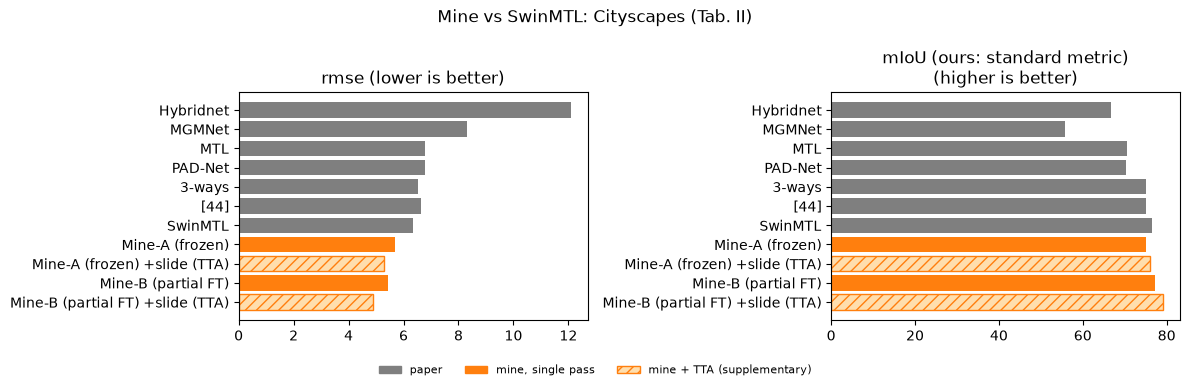

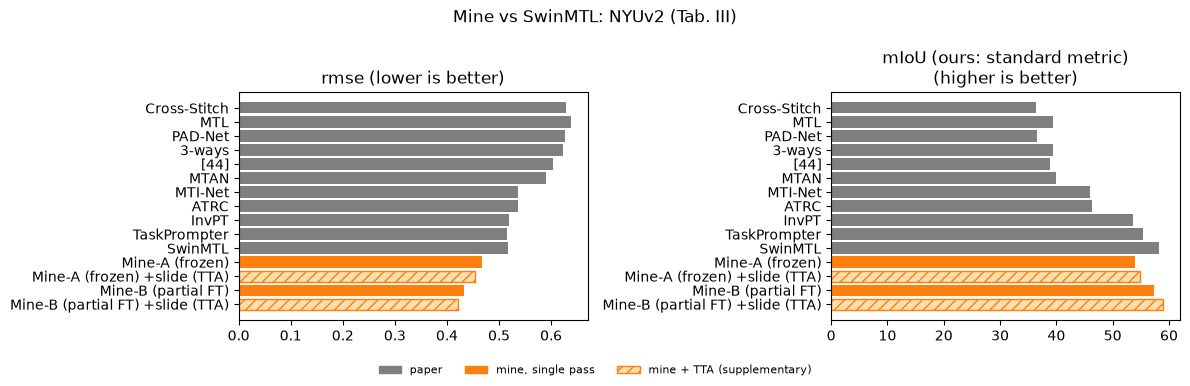

In [7]:
# Tab. I
rows = [dict(model=model, source="paper", **values) for model, values in PAPER["swinmtl_tab1"].items()]
for variant in CFG["variants"]:
    results = mine("cityscapes", variant, "cs_depth_512x1024")
    if results:
        metrics = {key: results[key] for key in ["abs_rel", "sq_rel", "rmse", "rmse_log", "d1", "d2", "d3"]}
        rows.append(dict(model=VARIANT_LABEL[variant], source="measured", res="512x1024", **metrics))
    results = mine("cityscapes", variant, "cs_depth_512x1024_slide")
    if results:
        metrics = {key: results[key] for key in ["abs_rel", "sq_rel", "rmse", "rmse_log", "d1", "d2", "d3"]}
        rows.append(dict(model=VARIANT_LABEL[variant] + " +slide (TTA)", source="measured, TTA", res="512x1024", **metrics))

print("SwinMTL Tab. I: Cityscapes depth (* = self-supervised in the paper)")
tab1 = show_table(rows, "swinmtl_tab1", highlight=True)

# Tab. II
rows = []
for model, (rmse, miou) in PAPER["swinmtl_tab2"].items():
    rows.append({"model": model, "source": "paper", "rmse": rmse, "mIoU (paper: as reported; ours: standard)": miou, "mIoU (ours: SwinMTL per-image)": None})
for variant in CFG["variants"]:
    results = mine("cityscapes", variant)
    if results:
        rows.append({
            "model": VARIANT_LABEL[variant],
            "source": "measured",
            "rmse": results["cs_depth_full"]["rmse"],
            "mIoU (paper: as reported; ours: standard)": results["cs_seg"]["mIoU"],
            "mIoU (ours: SwinMTL per-image)": results["cs_seg_swinmtl"]["mIoU"],
        })
        if "cs_depth_full_slide" in results:
            rows.append({
                "model": VARIANT_LABEL[variant] + " +slide (TTA)",
                "source": "measured, TTA",
                "rmse": results["cs_depth_full_slide"]["rmse"],
                "mIoU (paper: as reported; ours: standard)": results["cs_seg_slide"]["mIoU"],
                "mIoU (ours: SwinMTL per-image)": results["cs_seg_swinmtl_slide"]["mIoU"],
            })

print('SwinMTL Tab. II: Cityscapes MTL at 1024x2048 (mIoU: standard 19-class metric for my models; SwinMTL per-image shown for reference)')
tab2 = show_table(rows, "swinmtl_tab2", highlight=True)

# Tab. III
rows = []
for model, (rmse, miou) in PAPER["swinmtl_tab3"].items():
    rows.append({"model": model, "source": "paper", "rmse": rmse, "mIoU (paper: as reported; ours: standard)": miou, "mIoU (ours: SwinMTL per-image)": None})
for variant in CFG["variants"]:
    results = mine("nyu", variant)
    if results:
        rows.append({
            "model": VARIANT_LABEL[variant],
            "source": "measured",
            "rmse": results["nyu_depth"]["rmse"],
            "mIoU (paper: as reported; ours: standard)": results["nyu_seg"]["mIoU"],
            "mIoU (ours: SwinMTL per-image)": results["nyu_seg_swinmtl"]["mIoU"],
        })
        if "nyu_depth_slide" in results:
            rows.append({
                "model": VARIANT_LABEL[variant] + " +slide (TTA)",
                "source": "measured, TTA",
                "rmse": results["nyu_depth_slide"]["rmse"],
                "mIoU (paper: as reported; ours: standard)": results["nyu_seg_slide"]["mIoU"],
                "mIoU (ours: SwinMTL per-image)": results["nyu_seg_swinmtl_slide"]["mIoU"],
            })

print('SwinMTL Tab. III: NYUv2 MTL (40 classes; mIoU: standard metric for my models; SwinMTL per-image shown for reference)')
tab3 = show_table(rows, "swinmtl_tab3", highlight=True)

# Tab. V
rows = []
for model, (flops, params) in PAPER["swinmtl_tab5"].items():
    rows.append({"model": model, "source": "paper", "FLOPs (G, as reported)": flops, "params (M)": params})
for variant in CFG["variants"]:
    eff = EFF.get(("cityscapes", variant))
    if eff:
        rows.append({
            "model": VARIANT_LABEL[variant],
            "source": f"measured @ {eff['input']}",
            "FLOPs (G, as reported)": eff["GMACs"],
            "params (M)": eff["params_M"],
        })

print('SwinMTL Tab. V: model size (mine: GMACs at 512x1024; the input size of the paper FLOPs is not stated, so FLOPs are not comparable)')
tab5 = show_table(rows, "swinmtl_tab5", highlight=True)

bar_compare(tab2, [("rmse", True), ("mIoU (paper: as reported; ours: standard)", False, "mIoU (ours: standard metric)")], "Mine vs SwinMTL: Cityscapes (Tab. II)", "vs_swinmtl_cs")
bar_compare(tab3, [("rmse", True), ("mIoU (paper: as reported; ours: standard)", False, "mIoU (ours: standard metric)")], "Mine vs SwinMTL: NYUv2 (Tab. III)", "vs_swinmtl_nyu")

### Mine vs DINOv2 (single task, ViT-S/14)
DINOv2 evaluates *frozen* features with light heads (Tab. 10 and Tab. 11). For **depth**, variant A is the like-for-like comparison (frozen ViT-S/14 + DPT decoder, as DINOv2's DPT column); B shows the effect of fine-tuning the last blocks. For **segmentation** it is not: DINOv2's numbers come from a linear head (lin.), or a linear head on the last 4 layers at 640 px with multi-scale TTA (+ms), while mine use a DPT decoder (≈ 15.8 M trainable parameters), so part of the gap is the head.
- **NYUv2 depth (Tab. 11).** DINOv2's DPT column is a frozen ViT-S/14 + DPT decoder trained for depth only. Mine is the depth output of the MTL model, read off the same network. Both `nyu_depth` and `nyu_depth_flip` (flip TTA, supplementary) are shown; DINOv2 follows the Li et al. depth toolbox protocol (Eigen crop, 10 m cap).
- **Cityscapes segmentation (Tab. 10).** "lin." is single-scale; "+ms" uses the last 4 layers, multi-scale inputs and flip. Mine single-scale = `cs_seg`, mine +ms = `cs_seg_ms` (the same multi-scale + flip test).

**Note.** DINOv2 trains its NYU depth head on the ~24k-image NYU raw training set, whereas my model sees the 795 labelled images only. A gap in DINOv2's favour is therefore expected and comes from the training data, not the architecture.

DINOv2 Tab. 11: NYUv2 depth, RMSE


,source,NYU RMSE,"NYU RMSE (flip, TTA)","NYU RMSE (slide, TTA)"
model,,,,
DINOv2 ViT-S/14 lin. 1,paper (Tab. 11),0.449,—,—
DINOv2 ViT-S/14 lin. 4,paper (Tab. 11),0.417,—,—
DINOv2 ViT-S/14 DPT,paper (Tab. 11),0.356,—,—
Mine-A (frozen),measured,0.4671,0.4597,0.4537
Mine-B (partial FT),measured,0.4329,0.4255,0.4208


DINOv2 Tab. 10: Cityscapes segmentation, mIoU (19 classes)


,source,CS mIoU (single-scale / lin.),CS mIoU (+ms),"CS mIoU (slide, TTA)"
model,,,,
DINOv2 ViT-S/14,paper (Tab. 10),66.6,77.1,—
Mine-A (frozen),measured,74.99,76.23,76.13
Mine-B (partial FT),measured,77.26,78.81,79.21


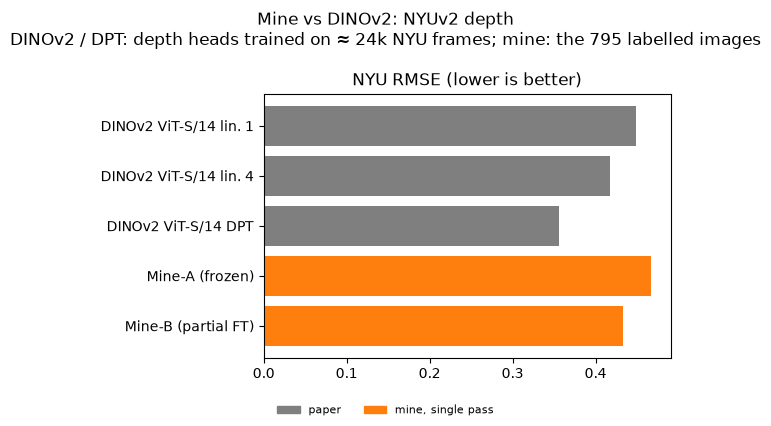

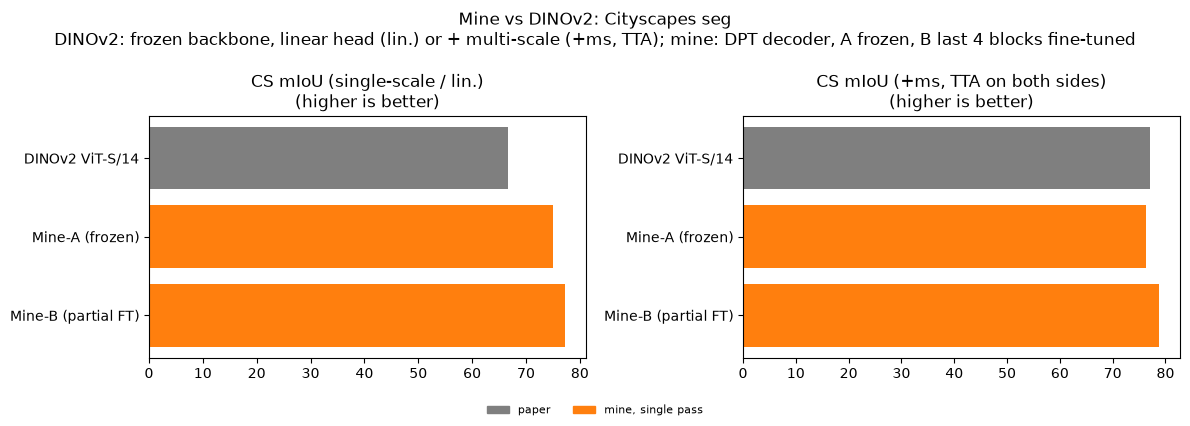

In [8]:
dinov2_depth = PAPER["dinov2_tab11_vits14"]
dinov2_seg = PAPER["dinov2_tab10_vits14"]

# NYUv2 depth (Tab. 11)
rows = []
for i, setting in enumerate(["lin. 1", "lin. 4", "DPT"]):
    rows.append({"model": f"DINOv2 ViT-S/14 {setting}", "source": "paper (Tab. 11)", "NYU RMSE": dinov2_depth["nyu"][i], "NYU RMSE (flip, TTA)": None, "NYU RMSE (slide, TTA)": None})
for variant in CFG["variants"]:
    results = mine("nyu", variant)
    if results:
        rows.append({
            "model": VARIANT_LABEL[variant],
            "source": "measured",
            "NYU RMSE": results["nyu_depth"]["rmse"],
            "NYU RMSE (flip, TTA)": results["nyu_depth_flip"]["rmse"],
            "NYU RMSE (slide, TTA)": results.get("nyu_depth_slide", {}).get("rmse"),
        })

print("DINOv2 Tab. 11: NYUv2 depth, RMSE")
dino_depth = show_table(rows, "dinov2_nyu_depth", highlight=True)

# Cityscapes segmentation (Tab. 10)
rows = [{
    "model": "DINOv2 ViT-S/14",
    "source": "paper (Tab. 10)",
    "CS mIoU (single-scale / lin.)": dinov2_seg["cityscapes"][0],
    "CS mIoU (+ms)": dinov2_seg["cityscapes"][1],
    "CS mIoU (slide, TTA)": None,
}]
for variant in CFG["variants"]:
    results = mine("cityscapes", variant)
    if results:
        rows.append({
            "model": VARIANT_LABEL[variant],
            "source": "measured",
            "CS mIoU (single-scale / lin.)": results["cs_seg"]["mIoU"],
            "CS mIoU (+ms)": results["cs_seg_ms"]["mIoU"],
            "CS mIoU (slide, TTA)": results.get("cs_seg_slide", {}).get("mIoU"),
        })

print("DINOv2 Tab. 10: Cityscapes segmentation, mIoU (19 classes)")
dino_seg = show_table(rows, "dinov2_cs_seg", highlight=True)

bar_compare(dino_depth, [("NYU RMSE", True)], "Mine vs DINOv2: NYUv2 depth", "vs_dinov2_nyu", note="DINOv2 / DPT: depth heads trained on ≈ 24k NYU frames; mine: the 795 labelled images")
bar_compare(dino_seg, [("CS mIoU (single-scale / lin.)", False), ("CS mIoU (+ms)", False, "CS mIoU (+ms, TTA on both sides)")], "Mine vs DINOv2: Cityscapes seg", "vs_dinov2_cs", note="DINOv2: frozen backbone, linear head (lin.) or + multi-scale (+ms, TTA); mine: DPT decoder, A frozen, B last 4 blocks fine-tuned")

### Mine vs DPT (single task)
DPT Tab. 2: DPT-Hybrid, pretrained on the MIX-6 meta-dataset (1.4 M images) and then fine-tuned on NYUv2, scored with the six standard metrics. Mine = the depth output of the NYU MTL models, under the same protocol (Eigen crop, 10 m). Both the no-TTA and the flip-TTA results are shown.

**Note.** DPT fine-tunes on the full NYUv2 raw training set, after pretraining on 1.4 M depth images, while I use 795 labelled images. The KITTI numbers of DPT Tab. 3 appear in 'Zero-shot details', next to my zero-shot transfer.

DPT Tab. 2: NYUv2 depth


,source,d1,d2,d3,abs_rel,rmse,log10
model,,,,,,,
DORN,paper (Tab. 2),0.828,0.965,0.992,0.115,0.509,0.051
VNL,paper (Tab. 2),0.875,0.976,0.994,0.111,0.416,0.048
BTS,paper (Tab. 2),0.885,0.978,0.994,0.11,0.392,0.047
DPT-Hybrid,paper (Tab. 2),0.904,0.988,0.998,0.11,0.357,0.045
Mine-A (frozen),measured,0.8323,0.976,0.9965,0.1373,0.4671,0.05664
Mine-A (frozen) +flip (TTA),measured,0.8381,0.9769,0.9967,0.1349,0.4597,0.05569
Mine-A (frozen) +slide (TTA),measured,0.8411,0.9786,0.997,0.1319,0.4537,0.05485
Mine-B (partial FT),measured,0.857,0.9823,0.997,0.1247,0.4329,0.05209
Mine-B (partial FT) +flip (TTA),measured,0.8619,0.9835,0.9971,0.1224,0.4255,0.05116


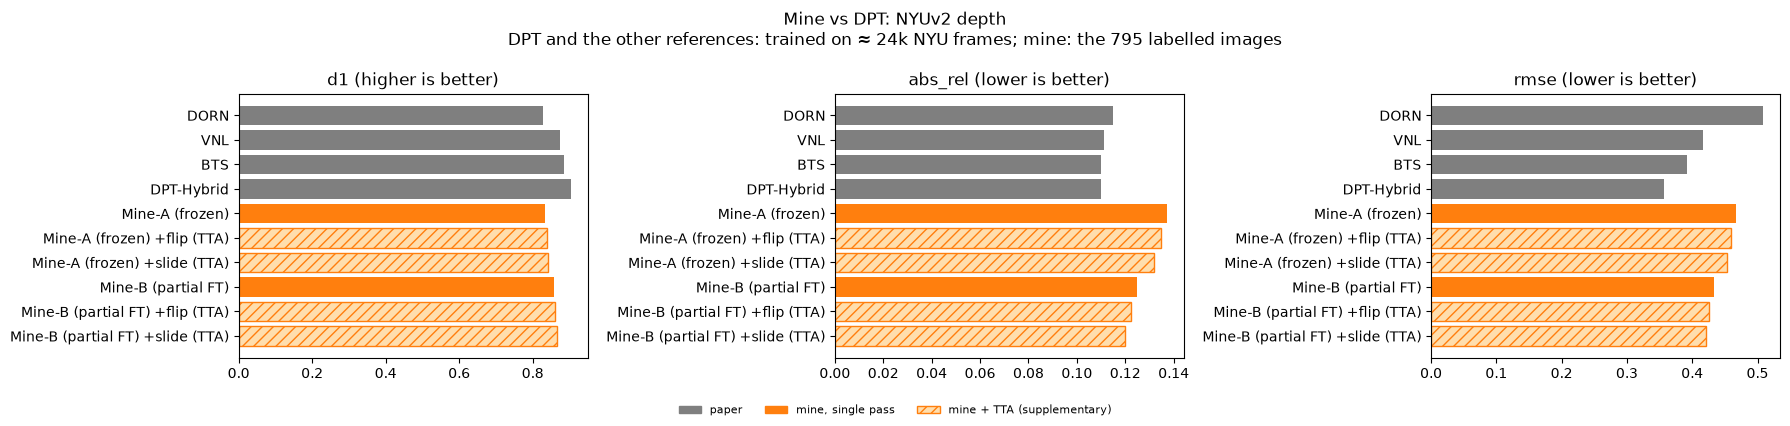

In [9]:
rows = [dict(model=model, source="paper (Tab. 2)", **values) for model, values in PAPER["dpt_tab2"].items()]

for variant in CFG["variants"]:
    results = mine("nyu", variant)
    if not results:
        continue

    for key, suffix in [("nyu_depth", ""), ("nyu_depth_flip", " +flip (TTA)"), ("nyu_depth_slide", " +slide (TTA)")]:
        if key not in results:
            continue
        metrics = {metric: results[key][metric] for metric in ["d1", "d2", "d3", "abs_rel", "rmse", "log10"]}
        rows.append(dict(model=VARIANT_LABEL[variant] + suffix, source="measured", **metrics))

print("DPT Tab. 2: NYUv2 depth")
dpt_nyu = show_table(rows, "dpt_nyu", highlight=True)
bar_compare(dpt_nyu, [("d1", False), ("abs_rel", True), ("rmse", True)], "Mine vs DPT: NYUv2 depth", "vs_dpt_nyu", note="DPT and the other references: trained on ≈ 24k NYU frames; mine: the 795 labelled images")

---
## All-in-one comparison

The three papers do not share all their benchmarks:

| | CS depth | CS seg | NYU depth | NYU seg | KITTI | SUN RGB-D | ADE20K | VOC | Pascal Ctx |
|---|---|---|---|---|---|---|---|---|---|
| SwinMTL | ✓ | ✓ | ✓ | ✓ | – | – | – | – | – |
| DINOv2 | – | ✓ | ✓ | – | ✓ | ✓ | ✓ | ✓ | – |
| DPT | – | – | ✓ | – | ✓ | – | ✓ | – | ✓ |
| **Mine** | ✓ | ✓ | ✓ | ✓ | **zero-shot** | **zero-shot** | **zero-shot, class subset** | **zero-shot, class subset** | **zero-shot, class subset** |

My models are trained only on Cityscapes and NYUv2. The other benchmarks are filled in by **evaluating the two models directly** (zero-shot):
- **KITTI** (outdoor depth) uses the Cityscapes models; **SUN RGB-D** (indoor depth) uses the NYU models, exactly DINOv2's NYU→SUN transfer setting.
  - *Camera normalisation*: each image is resized by $f_{train}/f_{test}$, so the apparent focal length matches the training one ($f_{CS}$ = 1131 px at 512×1024, $f_{NYU}$ = 519 px). The metric depth then transfers without rescaling.
  - Both the raw metric numbers and median-scaled ones (per-image median scaling) are reported. DPT's zero-shot Tab. 1 instead uses MiDaS's scale-and-shift alignment, so the median-scaled numbers are not comparable with it.
- **ADE20K / VOC / Pascal Context** have other label spaces. Predictions are mapped to the target classes that have a clear counterpart, and mIoU is computed **over those k classes only**. The mapping tables are in the next cell.
  - For VOC, every unmapped prediction counts as *background*, which is a VOC class.
  - For ADE20K and Pascal Context, unmapped predictions count as errors, and GT pixels of unmapped classes are ignored.

**Every cell of the final table is tagged.**
- *paper*: copied from a paper's table.
- *measured*: my model on that benchmark's protocol.
- *zero-shot*: my model transferred without training.

Zero-shot and class-subset numbers are **not comparable** with in-domain numbers trained on the full label set. They are shown for completeness and excluded from the ranking.

### Label-mapping tables for zero-shot segmentation
For each (training dataset → target dataset) pair, a dictionary `target class → [source classes]`. Only unambiguous one-to-one or many-to-one correspondences are kept.
Ambiguous classes are left out.

In [10]:
# target class -> source classes
TRANSFER = {
    ("cityscapes", "ade20k"): {
        "road": ["road"], "sidewalk": ["sidewalk"], "building": ["building"], "fence": ["fence"],
        "pole": ["pole"], "traffic light": ["traffic light"], "signboard": ["traffic sign"], "tree": ["vegetation"],
        "sky": ["sky"], "person": ["person", "rider"], "car": ["car"], "truck": ["truck"], "bus": ["bus"],
        "minibike": ["motorcycle"], "bicycle": ["bicycle"],
    },
    ("nyu", "ade20k"): {
        "wall": ["wall"], "floor": ["floor"], "cabinet": ["cabinet"], "bed": ["bed"], "chair": ["chair"],
        "sofa": ["sofa"], "table": ["table"], "door": ["door"], "windowpane": ["window"], "bookcase": ["bookshelf"],
        "painting": ["picture"], "counter": ["counter"], "blind": ["blinds"], "desk": ["desk"], "shelf": ["shelves"],
        "curtain": ["curtain"], "chest of drawers": ["dresser"], "pillow": ["pillow"], "mirror": ["mirror"],
        "rug": ["floor mat"], "ceiling": ["ceiling"], "book": ["books"], "refrigerator": ["refridgerator"],
        "television receiver": ["television"], "towel": ["towel"], "box": ["box"], "person": ["person"],
        "toilet": ["toilet"], "sink": ["sink"], "lamp": ["lamp"], "bathtub": ["bathtub"], "bag": ["bag"],
    },
    ("cityscapes", "voc2012"): {
        "bicycle": ["bicycle"], "bus": ["bus"], "car": ["car"], "motorbike": ["motorcycle"],
        "person": ["person", "rider"], "train": ["train"],
    },
    ("nyu", "voc2012"): {
        "chair": ["chair"], "diningtable": ["table"], "person": ["person"], "sofa": ["sofa"],
        "tvmonitor": ["television"],
    },
    ("cityscapes", "pcontext"): {
        "road": ["road"], "sidewalk": ["sidewalk"], "building": ["building"], "fence": ["fence"],
        "sign": ["traffic sign"], "tree": ["vegetation"], "sky": ["sky"], "person": ["person", "rider"], "car": ["car"],
        "truck": ["truck"], "bus": ["bus"], "motorbike": ["motorcycle"], "bicycle": ["bicycle"], "train": ["train"],
    },
    ("nyu", "pcontext"): {
        "wall": ["wall"], "floor": ["floor"], "cabinet": ["cabinet"], "bed": ["bed"], "chair": ["chair"],
        "sofa": ["sofa"], "table": ["table", "desk"], "door": ["door"], "window": ["window"],
        "shelves": ["shelves", "bookshelf"], "curtain": ["curtain"], "ceiling": ["ceiling"], "book": ["books"],
        "tvmonitor": ["television"], "person": ["person"], "bag": ["bag"], "cloth": ["clothes"], "light": ["lamp"],
    },
}

# target dataset -> (class names, background class)
TARGETS = {
    "ade20k": (ADE150_NAMES, None),
    "voc2012": (VOC_NAMES, "background"),
    "pcontext": (PC59_NAMES, None),
}


def make_transfer(source: str, target: str) -> Tuple[List[str], Tensor, Tensor]:
    """Look-up tables of a zero-shot transfer.

    Args:
        source: training dataset of the model ("cityscapes", "nyu").
        target: evaluation dataset ("ade20k", "voc2012", "pcontext").

    Returns:
        evaluated classes, prediction LUT (source id -> compact id), GT LUT (target id -> compact id or 255).
    """
    source_names = SOURCE_NAMES[source]
    target_names, background = TARGETS[target]
    mapping = TRANSFER[(source, target)]

    classes = list(mapping) + ([background] if background else [])

    # unmapped predictions go to background (VOC) or to an extra "none" class
    none_id = classes.index(background) if background else len(classes)

    source_lut = np.full(len(source_names), none_id, np.int64)
    for target_class, source_classes in mapping.items():
        for source_class in source_classes:
            source_lut[source_names.index(source_class)] = classes.index(target_class)

    target_lut = np.full(256, 255, np.int64)
    for target_class in classes:
        target_lut[target_names.index(target_class)] = classes.index(target_class)

    return classes, torch.from_numpy(source_lut), torch.from_numpy(target_lut)


for source, target in TRANSFER:
    print(f"{source} -> {target}: {len(make_transfer(source, target)[0])} evaluated classes")

cityscapes -> ade20k: 15 evaluated classes
nyu -> ade20k: 32 evaluated classes
cityscapes -> voc2012: 7 evaluated classes
nyu -> voc2012: 6 evaluated classes
cityscapes -> pcontext: 14 evaluated classes
nyu -> pcontext: 18 evaluated classes


### Zero-shot runners

- `eval_kitti_zeroshot` follows the BTS/DINOv2 KITTI protocol:
  1. KB crop to 352×1216 (top crop of height 352, centred width 1216);
  2. resize by $f_{CS}/f_{KITTI}$ ≈ 1.57;
  3. predict, and resize back;
  4. paste into a full-size canvas;
  5. score inside the Garg crop with GT in (1e-3, 80) m.
- `eval_sun_zeroshot`: resize by $f_{NYU}/f_{SUN}$, predict, resize back, score GT in (1e-3, 10) m.
- `eval_seg_transfer`:
  1. resize the short side to the training scale (512 for Cityscapes models, 480 for NYU models);
  2. predict, and resize to the GT size;
  3. map the prediction through `src_lut` and the GT through `tgt_lut`;
  4. compute the confusion-matrix mIoU over the k mapped classes.

In [11]:
def to_numpy(x) -> np.ndarray:
    return x.numpy() if torch.is_tensor(x) else np.asarray(x)


def iterate_eval(kind: str, limit: Optional[int]):
    """
    Iterate over an eval-only dataset (batch_size=None returns the raw samples).
    """
    dataset = make_eval_dataset(kind)
    n = len(dataset) if limit is None else min(limit, len(dataset))
    data_loader = DataLoader(Subset(dataset, range(n)), batch_size=None, num_workers=min(4, CFG["num_workers"]))
    return tqdm(data_loader, total=n, desc=f"zero-shot {kind}", leave=False)


@torch.no_grad()
def eval_kitti_zeroshot(model: nn.Module, limit: Optional[int] = None) -> dict:
    """
    Cityscapes model on KITTI Eigen: KB crop, focal normalisation, Garg crop, cap 80 m.
    """
    model.eval()

    # metrics init
    raw_meter = DepthMeter(1e-3, 80.0)
    median_meter = DepthMeter(1e-3, 80.0, median_scale=True)
    train_focal = CFG["datasets"]["cityscapes"]["fx_base"]

    for img, gt, focal in iterate_eval("kitti", limit):
        img = to_numpy(img)
        gt = torch.as_tensor(to_numpy(gt), device=device)
        H, W = gt.shape

        # KB crop 352x1216
        top = H - 352
        left = (W - 1216) // 2
        crop = np.ascontiguousarray(img[top:top + 352, left:left + 1216])

        # resize so that the focal length matches the training one
        s = train_focal / float(focal)
        x = prep_image(crop, (int(round(352 * s)), int(round(1216 * s))))
        depth = predict(model, x)[0]
        depth = F.interpolate(depth, size=(352, 1216), mode="bilinear", align_corners=False)[0, 0]

        # paste into a full-size canvas
        full_depth = torch.zeros(H, W, device=device)
        full_depth[top:top + 352, left:left + 1216] = depth

        # Garg crop
        garg_mask = torch.zeros(H, W, dtype=torch.bool, device=device)
        garg_mask[int(0.40810811 * H):int(0.99189189 * H), int(0.03594771 * W):int(0.96405229 * W)] = True

        raw_meter.update(full_depth, gt, garg_mask)
        median_meter.update(full_depth, gt, garg_mask)

    return dict(kitti_raw=raw_meter.result(), kitti_median=median_meter.result())


@torch.no_grad()
def eval_sun_zeroshot(model: nn.Module, limit: Optional[int] = None) -> dict:
    """
    NYU model on SUN RGB-D: focal normalisation, cap 10 m.
    """
    model.eval()

    # metrics init
    raw_meter = DepthMeter(1e-3, 10.0)
    median_meter = DepthMeter(1e-3, 10.0, median_scale=True)
    train_focal = CFG["datasets"]["nyu"]["fx_base"]

    for img, gt, fx in iterate_eval("sunrgbd", limit):
        img = to_numpy(img)
        gt = torch.as_tensor(to_numpy(gt), device=device)
        H, W = gt.shape

        s = train_focal / float(fx)
        depth = predict(model, prep_image(img, (int(round(H * s)), int(round(W * s)))))[0]
        depth = F.interpolate(depth, size=(H, W), mode="bilinear", align_corners=False)[0, 0]

        raw_meter.update(depth, gt)
        median_meter.update(depth, gt)

    return dict(sun_raw=raw_meter.result(), sun_median=median_meter.result())


@torch.no_grad()
def eval_seg_transfer(model: nn.Module, source: str, target: str, limit: Optional[int] = None) -> dict:
    """Zero-shot segmentation over the mapped classes.

    Args:
        model: model trained on source.
        source: "cityscapes" or "nyu".
        target: "ade20k", "voc2012" or "pcontext".
        limit: evaluate only the first images.
    """
    model.eval()
    classes, source_lut, target_lut = make_transfer(source, target)
    meter = SegMeter(len(classes) + 1)
    short_side = CFG["datasets"][source]["base_size"][0]   # training scale

    for img, gt in iterate_eval(target, limit):
        img = to_numpy(img)
        gt = torch.as_tensor(to_numpy(gt)).long()
        H, W = gt.shape

        s = short_side / min(H, W)
        probs = predict(model, prep_image(img, (int(round(H * s)), int(round(W * s)))))[1]
        pred = F.interpolate(probs, size=(H, W), mode="bilinear", align_corners=False)[0].argmax(0).cpu()

        meter.update(source_lut[pred], target_lut[gt.clamp(0, 255)])

    results = meter.result(classes=range(len(classes)))
    return dict(
        mIoU=results["mIoU"],
        pixAcc=results["pixAcc"],
        n_classes=len(classes),
        classes=classes,
        per_class_iou=results["per_class_iou"]
    )

### Run the zero-shot evaluations

In [12]:
def zero_shot_run(dataset: str, variant: str, force: bool = False) -> dict:
    """Run the zero-shot evaluations of a model; cached in results/eval/<run>_zeroshot.json.

    Args:
        dataset: training dataset of the model.
        variant: "frozen" or "partial_ft".
        force: recompute everything.
    """
    out_path = CFG["results_root"] / "eval" / f"{run_name(dataset, variant)}_zeroshot.json"
    results = {} if force else load_json(out_path, {})

    if not (CFG["ckpt_root"] / run_name(dataset, variant) / "final.pt").exists():
        return results

    # depth transfer: Cityscapes -> KITTI, NYU -> SUN RGB-D
    if dataset == "cityscapes":
        jobs = [("kitti", lambda m: eval_kitti_zeroshot(m))]
    else:
        jobs = [("sunrgbd", lambda m: eval_sun_zeroshot(m))]

    # segmentation transfer on the mapped classes
    for target in ["ade20k", "voc2012", "pcontext"]:
        jobs.append((target, lambda m, t=target: {f"{t}_subset": eval_seg_transfer(m, dataset, t)}))

    model = None
    for kind, job in jobs:
        already_done = any(key.startswith(kind[:3]) for key in results)
        if not CFG["zero_shot"][kind] or already_done:
            continue

        try:
            if model is None:
                model = load_trained(dataset, variant)
            results.update(job(model))
            save_json(results, out_path)
        except (FileNotFoundError, StopIteration) as e:
            print(f"{run_name(dataset, variant)} / {kind}: skipped ({type(e).__name__}: {e})")

    del model
    return results


ZS = {}
for dataset, variant in RUNS:
    ZS[(dataset, variant)] = zero_shot_run(dataset, variant)

    for key, values in ZS[(dataset, variant)].items():
        if "rmse" in values:
            message = f"RMSE: {values['rmse']:.3f}, AbsRel: {values['abs_rel']:.3f}, d1: {values['d1']:.3f}"
        else:
            message = f"mIoU: {values['mIoU']:.2f} over {values['n_classes']} classes"
        print(f"{run_name(dataset, variant)} - {key}: {message}")

cityscapes_frozen - kitti_raw: RMSE: 3.769, AbsRel: 0.122, d1: 0.865
cityscapes_frozen - kitti_median: RMSE: 3.779, AbsRel: 0.114, d1: 0.884
cityscapes_frozen - ade20k_subset: mIoU: 57.75 over 15 classes
cityscapes_frozen - voc2012_subset: mIoU: 68.65 over 7 classes
cityscapes_frozen - pcontext_subset: mIoU: 54.05 over 14 classes
cityscapes_partial_ft - kitti_raw: RMSE: 3.951, AbsRel: 0.125, d1: 0.858
cityscapes_partial_ft - kitti_median: RMSE: 3.677, AbsRel: 0.104, d1: 0.906
cityscapes_partial_ft - ade20k_subset: mIoU: 60.94 over 15 classes
cityscapes_partial_ft - voc2012_subset: mIoU: 70.12 over 7 classes
cityscapes_partial_ft - pcontext_subset: mIoU: 58.32 over 14 classes
nyu_frozen - sun_raw: RMSE: 0.630, AbsRel: 0.226, d1: 0.724
nyu_frozen - sun_median: RMSE: 0.540, AbsRel: 0.176, d1: 0.813
nyu_frozen - ade20k_subset: mIoU: 43.76 over 32 classes
nyu_frozen - voc2012_subset: mIoU: 42.63 over 6 classes
nyu_frozen - pcontext_subset: mIoU: 34.23 over 18 classes
nyu_partial_ft - sun_ra

### Master table and rank heat-map
One table with **all models × all benchmarks**. Each cell shows the value and its tag: *paper*, *measured* (*mean of 3* for the final model), *measured, TTA*, *zero-shot* (with the source model and number of classes), or a reason why the value is *not comparable*. The rank heat-map ranks the models within each column, using **only single-pass, like-for-like cells**. Hatched cells are shown but not ranked:
- **zero-shot** transfer (mine, and DINOv2's NYU→SUN number): a different protocol from the in-domain results;
- **TTA** rows (sliding window): supplementary only, never compared with single-pass numbers;
- values marked **not comparable**: SwinMTL's FLOPs (input size not stated) and DINOv2's parameter count (backbone only).

A column is coloured only if it contains, among the ranked cells, at least one paper result **and** one of my models. Otherwise the colours would compare only papers with each other (e.g. ADE20K, KITTI) or only my own runs with each other (e.g. GMACs).

**Column definitions.**
- **Resolutions:** CS AbsRel is at 512×1024 (SwinMTL Tab. I); CS RMSE and CS mIoU are at the full 1024×2048 (Tab. II).
- **mIoU:** my models use the standard metric. SwinMTL's numbers are as reported. DINOv2's CS mIoU is its single-scale linear probe on frozen features (Tab. 10, "lin.").
- **Depth references:** DINOv2's NYU, KITTI and SUN numbers are from its DPT-head column (Tab. 11). DPT-Hybrid's KITTI numbers are from a model trained on KITTI (DPT Tab. 3), while mine are zero-shot.
- **ADE20K / VOC / Pascal Context:** the papers report the full benchmarks (all classes). Mine are zero-shot on the mapped class subsets only ('Label-mapping tables for zero-shot segmentation'), taking the better of the Cityscapes and NYU models; the cell tag gives the source model and the number of classes. These cells are never ranked.
- **Params / GMACs:** total parameters; MACs measured at 512×1024 for my models.

,CS AbsRel,CS RMSE,CS mIoU,NYU RMSE,NYU AbsRel,NYU δ1,NYU mIoU,KITTI RMSE,KITTI AbsRel,SUN RMSE,ADE20K mIoU,VOC mIoU,PC mIoU,Params (M),GMACs
SwinMTL (Swin-V2-B),0.089 (paper),6.352 (paper),76.41 (paper),0.5179 (paper),—,—,58.14 (paper),—,—,—,—,—,—,87.38 (paper),"65 (paper; input size not stated, not comparable)"
DINOv2 ViT-S/14 (frozen),—,—,66.6 (paper),0.356 (paper),—,—,—,2.34 (paper),—,"0.409 (paper, NYU→SUN zero-shot)",44.3 (paper),81.1 (paper),—,"22.1 (model code; backbone only, not comparable)",—
DPT-Hybrid,—,—,—,0.357 (paper),0.11 (paper),0.904 (paper),—,2.573 (paper),0.062 (paper),—,49.02 (paper),—,60.46 (paper),123 (paper),—
DPT-Large,—,—,—,—,—,—,—,—,—,—,47.63 (paper),—,—,343 (paper),—
Mine-A (frozen),0.1259 (measured),5.693 (measured),74.99 (measured),0.4671 (measured),0.1373 (measured),0.8323 (measured),53.88 (measured),3.769 (zero-shot),0.122 (zero-shot),0.6299 (zero-shot),"57.75 (zero-shot, CS model, 15 cls)","68.65 (zero-shot, CS model, 7 cls)","54.05 (zero-shot, CS model, 14 cls)",37.81 (measured),475.7 (measured @512x1024)
Mine-B (partial FT),0.1221 (measured),5.453 (measured),77.26 (measured),0.4329 (measured),0.1247 (measured),0.857 (measured),57.27 (measured),3.951 (zero-shot),0.1249 (zero-shot),0.6113 (zero-shot),"60.94 (zero-shot, CS model, 15 cls)","70.12 (zero-shot, CS model, 7 cls)","58.32 (zero-shot, CS model, 14 cls)",37.81 (measured),475.7 (measured @512x1024)
Mine-A (frozen) +slide (TTA),"0.1025 (measured, TTA)","5.279 (measured, TTA)","76.13 (measured, TTA)","0.4537 (measured, TTA)","0.1319 (measured, TTA)","0.8411 (measured, TTA)","54.79 (measured, TTA)",—,—,—,—,—,—,—,—
Mine-B (partial FT) +slide (TTA),"0.08927 (measured, TTA)","4.893 (measured, TTA)","79.21 (measured, TTA)","0.4208 (measured, TTA)","0.1197 (measured, TTA)","0.8657 (measured, TTA)","59 (measured, TTA)",—,—,—,—,—,—,—,—


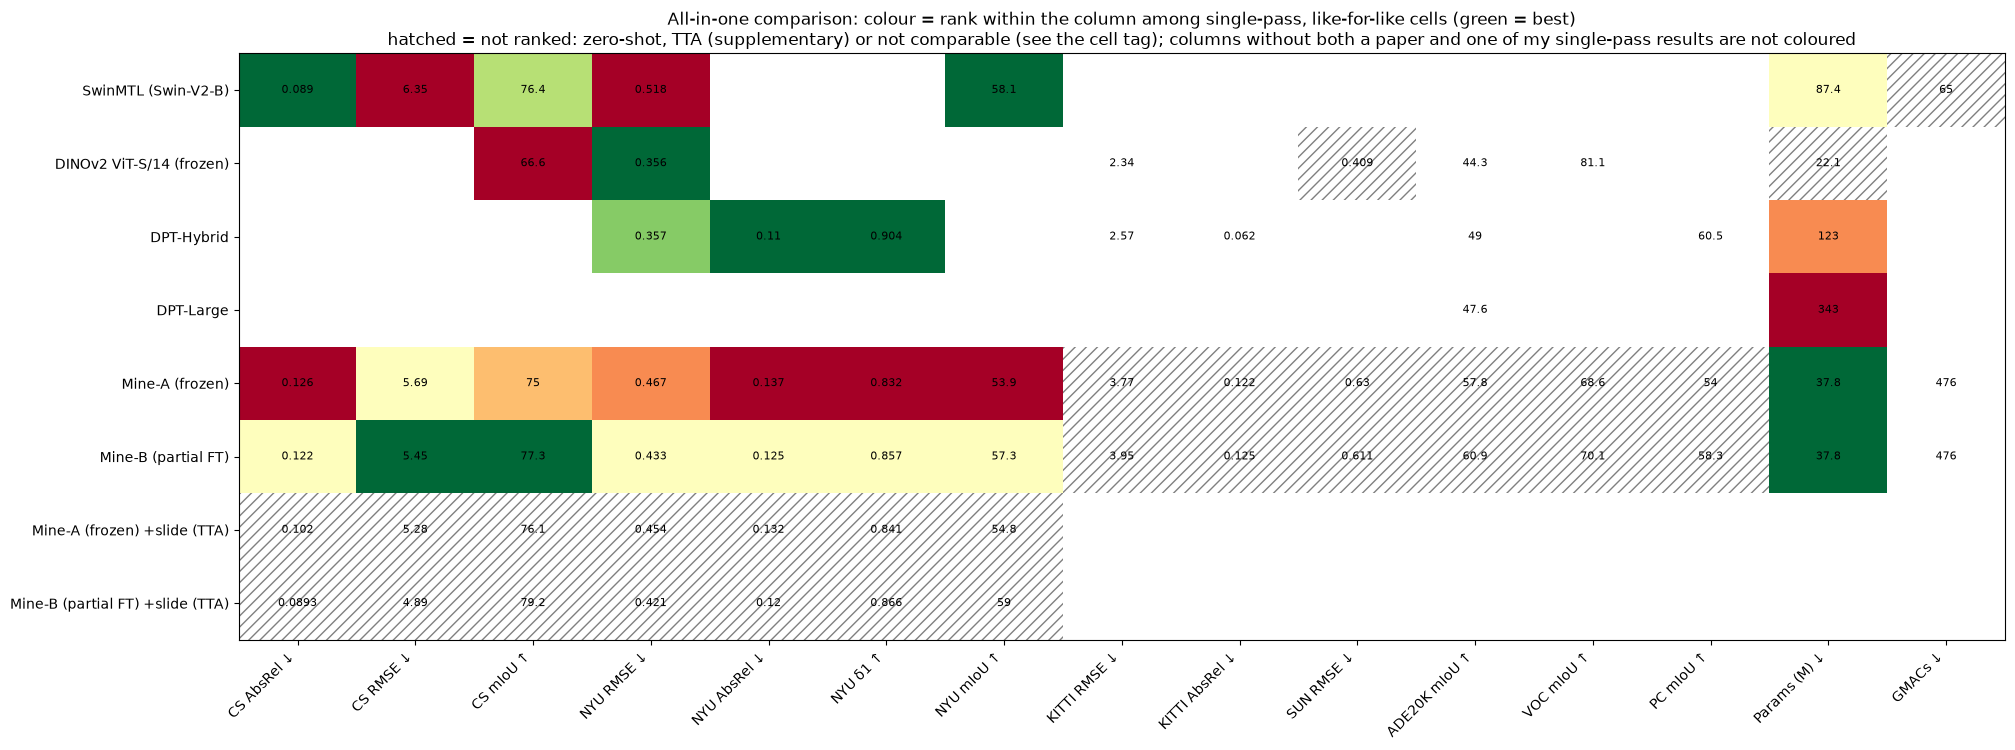

In [13]:
# (column, lower is better)
MASTER_COLS = [
    ("CS AbsRel", True), ("CS RMSE", True), ("CS mIoU", False), ("NYU RMSE", True), ("NYU AbsRel", True),
    ("NYU δ1", False), ("NYU mIoU", False), ("KITTI RMSE", True), ("KITTI AbsRel", True), ("SUN RMSE", True),
    ("ADE20K mIoU", False), ("VOC mIoU", False), ("PC mIoU", False), ("Params (M)", True), ("GMACs", True),
]


def build_master() -> dict:
    """
    Cells of the all-in-one table: model -> column -> (value, tag).
    """
    cells = defaultdict(dict)

    # paper numbers
    cells["SwinMTL (Swin-V2-B)"].update({
        "CS AbsRel": (PAPER["swinmtl_tab1"]["SwinMTL"]["abs_rel"], "paper"), "CS RMSE": (PAPER["swinmtl_tab2"]["SwinMTL"][0], "paper"), "CS mIoU": (PAPER["swinmtl_tab2"]["SwinMTL"][1], "paper"),
        "NYU RMSE": (PAPER["swinmtl_tab3"]["SwinMTL"][0], "paper"), "NYU mIoU": (PAPER["swinmtl_tab3"]["SwinMTL"][1], "paper"), "Params (M)": (PAPER["swinmtl_tab5"]["SwinMTL w/ Swin-B"][1], "paper"),
        "GMACs": (PAPER["swinmtl_tab5"]["SwinMTL w/ Swin-B"][0], "paper; input size not stated, not comparable"),
    })
    cells["DINOv2 ViT-S/14 (frozen)"].update({
        "NYU RMSE": (PAPER["dinov2_tab11_vits14"]["nyu"][2], "paper"),
        "KITTI RMSE": (PAPER["dinov2_tab11_vits14"]["kitti"][2], "paper"),
        "SUN RMSE": (PAPER["dinov2_tab11_vits14"]["sun"][2], "paper, NYU→SUN zero-shot"),
        "CS mIoU": (PAPER["dinov2_tab10_vits14"]["cityscapes"][0], "paper"),
        "ADE20K mIoU": (PAPER["dinov2_tab10_vits14"]["ade20k"][0], "paper"),
        "VOC mIoU": (PAPER["dinov2_tab10_vits14"]["voc2012"][0], "paper"),
        "Params (M)": (22.1, "model code; backbone only, not comparable"),
    })
    cells["DPT-Hybrid"].update({
        "NYU RMSE": (PAPER["dpt_tab2"]["DPT-Hybrid"]["rmse"], "paper"), "NYU AbsRel": (PAPER["dpt_tab2"]["DPT-Hybrid"]["abs_rel"], "paper"), "NYU δ1": (PAPER["dpt_tab2"]["DPT-Hybrid"]["d1"], "paper"),
        "KITTI RMSE": (PAPER["dpt_tab3"]["DPT-Hybrid"]["rmse"], "paper"), "KITTI AbsRel": (PAPER["dpt_tab3"]["DPT-Hybrid"]["abs_rel"], "paper"), "ADE20K mIoU": (PAPER["dpt_tab4"]["DPT-Hybrid"][1], "paper"),
        "PC mIoU": (PAPER["dpt_tab5"]["DPT-Hybrid"][1], "paper"), "Params (M)": (PAPER["dpt_tab9"]["DPT-Hybrid"][0], "paper"),
    })
    cells["DPT-Large"].update({"ADE20K mIoU": (PAPER["dpt_tab4"]["DPT-Large"][1], "paper"), "Params (M)": (PAPER["dpt_tab9"]["DPT-Large"][0], "paper")})

    # my models
    for variant in CFG["variants"]:
        row = cells[VARIANT_LABEL[variant]]
        cs_results = mine("cityscapes", variant)
        nyu_results = mine("nyu", variant)
        cs_zero_shot = ZS.get(("cityscapes", variant), {})
        nyu_zero_shot = ZS.get(("nyu", variant), {})

        if cs_results:
            row["CS AbsRel"] = (cs_results["cs_depth_512x1024"]["abs_rel"], "measured")
            row["CS RMSE"] = (cs_results["cs_depth_full"]["rmse"], "measured")
            row["CS mIoU"] = (cs_results["cs_seg"]["mIoU"], "measured")

        if nyu_results:
            row["NYU RMSE"] = (nyu_results["nyu_depth"]["rmse"], "measured")
            row["NYU AbsRel"] = (nyu_results["nyu_depth"]["abs_rel"], "measured")
            row["NYU δ1"] = (nyu_results["nyu_depth"]["d1"], "measured")
            row["NYU mIoU"] = (nyu_results["nyu_seg"]["mIoU"], "measured")

        if "kitti_raw" in cs_zero_shot:
            row["KITTI RMSE"] = (cs_zero_shot["kitti_raw"]["rmse"], "zero-shot")
            row["KITTI AbsRel"] = (cs_zero_shot["kitti_raw"]["abs_rel"], "zero-shot")

        if "sun_raw" in nyu_zero_shot:
            row["SUN RMSE"] = (nyu_zero_shot["sun_raw"]["rmse"], "zero-shot")

        # best of the Cityscapes / NYU model on each class subset
        for col, key in [("ADE20K mIoU", "ade20k_subset"), ("VOC mIoU", "voc2012_subset"), ("PC mIoU", "pcontext_subset")]:
            candidates = []
            for source_name, zero_shot in [("CS", cs_zero_shot), ("NYU", nyu_zero_shot)]:
                if key in zero_shot:
                    candidates.append((source_name, zero_shot[key]))

            if candidates:
                source_name, best = max(candidates, key=lambda c: c[1]["mIoU"])
                row[col] = (best["mIoU"], f"zero-shot, {source_name} model, {best['n_classes']} cls")

        eff = EFF.get(("cityscapes", variant))
        if eff:
            row["Params (M)"] = (eff["params_M"], "measured")
            row["GMACs"] = (eff["GMACs"], "measured @512x1024")

    # my models with sliding-window TTA (training benchmarks only)
    for variant in CFG["variants"]:
        cs_results = mine("cityscapes", variant) or {}
        nyu_results = mine("nyu", variant) or {}
        row = {}
        if "cs_depth_full_slide" in cs_results:
            row["CS AbsRel"] = (cs_results["cs_depth_512x1024_slide"]["abs_rel"], "measured, TTA")
            row["CS RMSE"] = (cs_results["cs_depth_full_slide"]["rmse"], "measured, TTA")
            row["CS mIoU"] = (cs_results["cs_seg_slide"]["mIoU"], "measured, TTA")
        if "nyu_depth_slide" in nyu_results:
            row["NYU RMSE"] = (nyu_results["nyu_depth_slide"]["rmse"], "measured, TTA")
            row["NYU AbsRel"] = (nyu_results["nyu_depth_slide"]["abs_rel"], "measured, TTA")
            row["NYU δ1"] = (nyu_results["nyu_depth_slide"]["d1"], "measured, TTA")
            row["NYU mIoU"] = (nyu_results["nyu_seg_slide"]["mIoU"], "measured, TTA")
        if row:
            cells[VARIANT_LABEL[variant] + " +slide (TTA)"].update(row)

    return cells


def not_ranked(tag: str) -> bool:
    """Cells excluded from the ranking: zero-shot transfer, test-time augmentation, and values that are not like-for-like."""
    return any(key in tag for key in ("zero-shot", "TTA", "not comparable"))


def show_master(cells: dict) -> None:
    """
    Display the all-in-one table and the rank heat-map (cells for which not_ranked(tag) is true are hatched and not ranked).
    """
    models = list(cells)
    columns = [col for col, _ in MASTER_COLS]

    # text table
    text_rows = []
    for model in models:
        text_row = []
        for col in columns:
            if col in cells[model]:
                value, tag = cells[model][col]
                text_row.append(f"{value:.4g} ({tag})")
            else:
                text_row.append("—")
        text_rows.append(text_row)

    text = pd.DataFrame(text_rows, index=models, columns=columns)
    text.to_csv(COMPARE_DIR / "master_table.csv")
    display(text)

    # numeric values used for the ranking (zero-shot excluded)
    values = np.full((len(models), len(MASTER_COLS)), np.nan)
    is_zero_shot = np.zeros_like(values, dtype=bool)
    for i, model in enumerate(models):
        for j, col in enumerate(columns):
            if col in cells[model]:
                value, tag = cells[model][col]
                is_zero_shot[i, j] = not_ranked(tag)
                if not is_zero_shot[i, j]:
                    values[i, j] = value

    # rank within each column: 0 = best, 1 = worst
    ranks = np.full_like(values, np.nan)
    for j, (_, lower_better) in enumerate(MASTER_COLS):
        column = values[:, j]
        available = ~np.isnan(column)
        # colour a column only if it compares at least one of my models with at least one paper result
        has_mine = any(available[i] and models[i].startswith("Mine") for i in range(len(models)))
        has_paper = any(available[i] and not models[i].startswith("Mine") for i in range(len(models)))
        if has_mine and has_paper and available.sum() > 1:
            order = pd.Series(column[available]).rank(ascending=lower_better, method="min").values
            ranks[available, j] = (order - 1) / (available.sum() - 1)

    # heat-map
    fig, ax = plt.subplots()
    fig.set_size_inches(1.15 * len(MASTER_COLS) + 3, 0.7 * len(models) + 2)
    ax.imshow(np.ma.masked_invalid(ranks), cmap="RdYlGn_r", vmin=0, vmax=1, aspect="auto")

    for i, model in enumerate(models):
        for j, col in enumerate(columns):
            if col not in cells[model]:
                continue
            if is_zero_shot[i, j]:
                ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, hatch="///", edgecolor="gray", lw=0))
            ax.text(j, i, f"{cells[model][col][0]:.3g}", ha="center", va="center", fontsize=8)

    ax.set_xticks(range(len(MASTER_COLS)))
    ax.set_xticklabels([f"{col} {'↓' if lower else '↑'}" for col, lower in MASTER_COLS], rotation=45, ha="right")
    ax.set_yticks(range(len(models)))
    ax.set_yticklabels(models)
    ax.set_title("All-in-one comparison: colour = rank within the column among single-pass, like-for-like cells (green = best)\n"
                 "hatched = not ranked: zero-shot, TTA (supplementary) or not comparable (see the cell tag); columns without both a paper and one of my single-pass results are not coloured")

    plt.tight_layout()
    fig.savefig(COMPARE_DIR / "master_heatmap.png", dpi=130)
    plt.show()


MASTER = build_master()
show_master(MASTER)

### Zero-shot details (KITTI vs DPT Tab. 3 and DINOv2, SUN RGB-D vs DINOv2)
The full depth metrics of the zero-shot transfers, raw and median-scaled, next to the in-domain paper numbers for reference.

In [14]:
# KITTI
rows = [dict(model=model, source="paper, in-domain (DPT Tab. 3)", **values) for model, values in PAPER["dpt_tab3"].items()]
rows.append(dict(model="DINOv2 ViT-S/14 DPT", source="paper, in-domain (Tab. 11)", rmse=PAPER["dinov2_tab11_vits14"]["kitti"][2]))

for variant in CFG["variants"]:
    zero_shot = ZS.get(("cityscapes", variant), {})
    for key, tag in [("kitti_raw", "zero-shot raw"), ("kitti_median", "zero-shot median-scaled")]:
        if key in zero_shot:
            metrics = {metric: zero_shot[key][metric] for metric in ["d1", "d2", "d3", "abs_rel", "rmse", "rmse_log"]}
            rows.append(dict(model=f"{VARIANT_LABEL[variant]} ({tag})", source="measured", **metrics))

print("KITTI Eigen test (652)")
show_table(rows, "kitti_zeroshot", highlight=True)

# SUN RGB-D
rows = []
for setting, rmse in zip(["lin. 1", "lin. 4", "DPT"], PAPER["dinov2_tab11_vits14"]["sun"]):
    rows.append(dict(model=f"DINOv2 ViT-S/14 {setting}", source="paper, NYU->SUN (Tab. 11)", rmse=rmse))

for variant in CFG["variants"]:
    zero_shot = ZS.get(("nyu", variant), {})
    for key, tag in [("sun_raw", "NYU->SUN raw"), ("sun_median", "NYU->SUN median-scaled")]:
        if key in zero_shot:
            metrics = {metric: zero_shot[key][metric] for metric in ["d1", "abs_rel", "rmse", "rmse_log"]}
            rows.append(dict(model=f"{VARIANT_LABEL[variant]} ({tag})", source="measured", **metrics))

print("SUN RGB-D test (NYUdata scenes excluded)")
show_table(rows, "sun_zeroshot", highlight=True)

# segmentation on the class subsets
rows = []
for variant in CFG["variants"]:
    for dataset in ["cityscapes", "nyu"]:
        for target in ["ade20k", "voc2012", "pcontext"]:
            zero_shot = ZS.get((dataset, variant), {}).get(f"{target}_subset")
            if zero_shot:
                rows.append(dict(
                    model=f"{VARIANT_LABEL[variant]} [{dataset}->{target}]",
                    source="zero-shot subset",
                    n_classes=zero_shot["n_classes"],
                    mIoU=zero_shot["mIoU"],
                    pixAcc=zero_shot["pixAcc"]
                ))

if rows:
    print("Zero-shot segmentation over the mapped class subsets")
    show_table(rows, "seg_zeroshot", highlight=True)

KITTI Eigen test (652)


,source,d1,d2,d3,abs_rel,rmse,rmse_log
model,,,,,,,
DORN,"paper, in-domain (DPT Tab. 3)",0.932,0.984,0.994,0.072,2.626,0.12
VNL,"paper, in-domain (DPT Tab. 3)",0.938,0.99,0.998,0.072,3.258,0.117
BTS,"paper, in-domain (DPT Tab. 3)",0.956,0.993,0.998,0.059,2.756,0.096
DPT-Hybrid,"paper, in-domain (DPT Tab. 3)",0.959,0.995,0.999,0.062,2.573,0.092
DINOv2 ViT-S/14 DPT,"paper, in-domain (Tab. 11)",—,—,—,—,2.34,—
Mine-A (frozen) (zero-shot raw),measured,0.8647,0.9797,0.9958,0.122,3.769,0.1584
Mine-A (frozen) (zero-shot median-scaled),measured,0.8838,0.9845,0.9969,0.1144,3.779,0.1485
Mine-B (partial FT) (zero-shot raw),measured,0.8577,0.9823,0.9965,0.1249,3.951,0.1556
Mine-B (partial FT) (zero-shot median-scaled),measured,0.9058,0.9886,0.9978,0.1036,3.677,0.1361


SUN RGB-D test (NYUdata scenes excluded)


,source,rmse,d1,abs_rel,rmse_log
model,,,,,
DINOv2 ViT-S/14 lin. 1,"paper, NYU->SUN (Tab. 11)",0.477,—,—,—
DINOv2 ViT-S/14 lin. 4,"paper, NYU->SUN (Tab. 11)",0.431,—,—,—
DINOv2 ViT-S/14 DPT,"paper, NYU->SUN (Tab. 11)",0.409,—,—,—
Mine-A (frozen) (NYU->SUN raw),measured,0.6299,0.7235,0.2265,0.2559
Mine-A (frozen) (NYU->SUN median-scaled),measured,0.5396,0.8125,0.1761,0.2185
Mine-B (partial FT) (NYU->SUN raw),measured,0.6113,0.7483,0.2146,0.2458
Mine-B (partial FT) (NYU->SUN median-scaled),measured,0.519,0.8358,0.1679,0.209


Zero-shot segmentation over the mapped class subsets


,source,n_classes,mIoU,pixAcc
model,,,,
Mine-A (frozen) [cityscapes->ade20k],zero-shot subset,15,57.75,86.99
Mine-A (frozen) [cityscapes->voc2012],zero-shot subset,7,68.65,95.97
Mine-A (frozen) [cityscapes->pcontext],zero-shot subset,14,54.05,75.32
Mine-A (frozen) [nyu->ade20k],zero-shot subset,32,43.76,73.54
Mine-A (frozen) [nyu->voc2012],zero-shot subset,6,42.63,89.68
Mine-A (frozen) [nyu->pcontext],zero-shot subset,18,34.23,58.72
Mine-B (partial FT) [cityscapes->ade20k],zero-shot subset,15,60.94,87.5
Mine-B (partial FT) [cityscapes->voc2012],zero-shot subset,7,70.12,96.42
Mine-B (partial FT) [cityscapes->pcontext],zero-shot subset,14,58.32,81.66


### Qualitative results
Three fixed test images per dataset, showing RGB, GT depth, depth from A and B, GT segmentation, and segmentation from A and B.

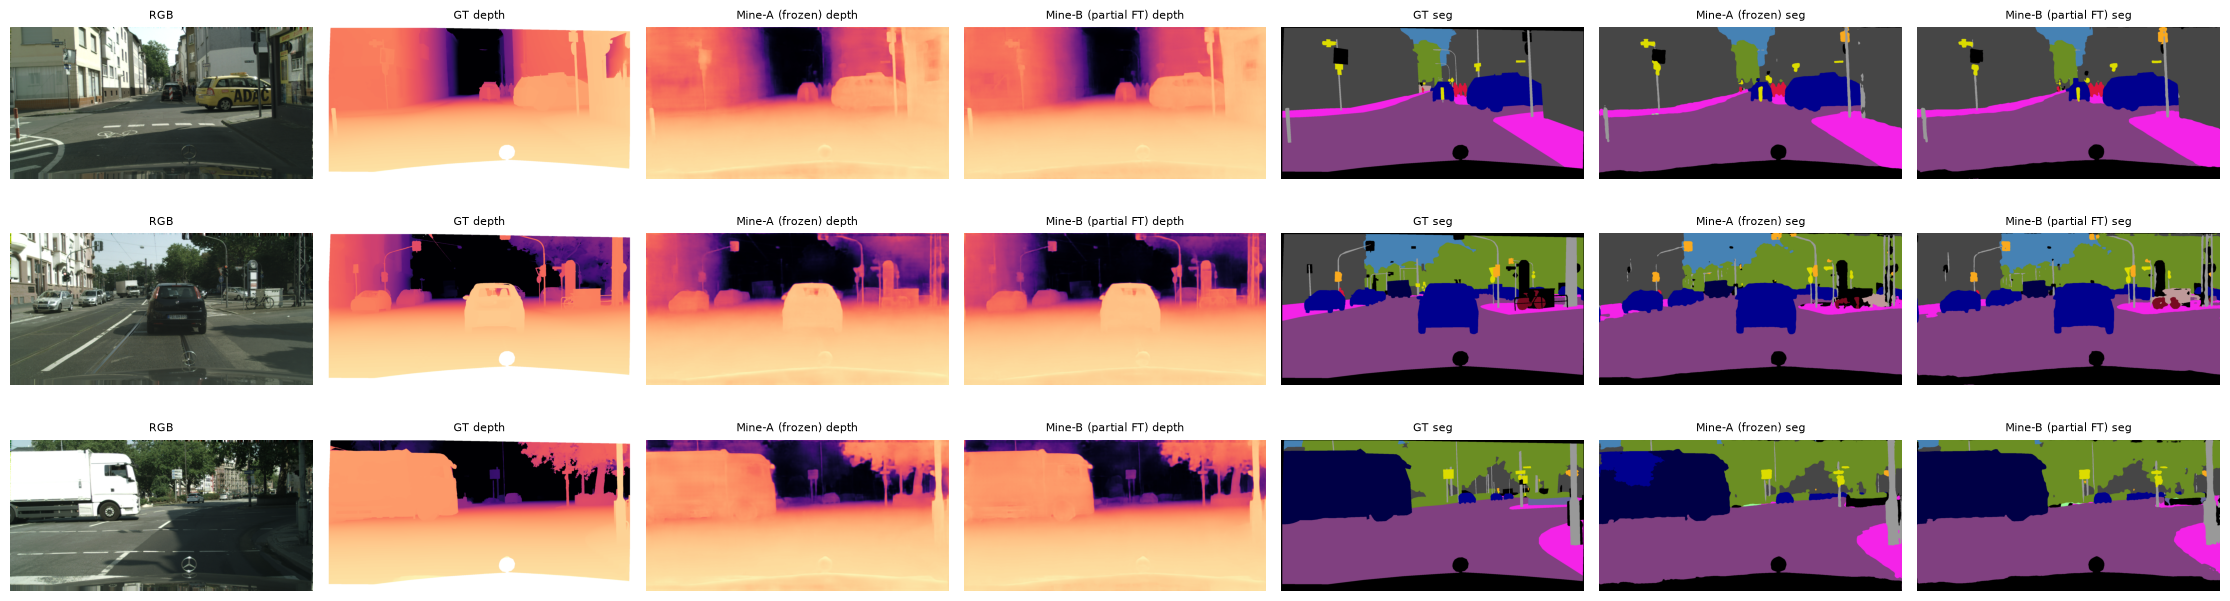

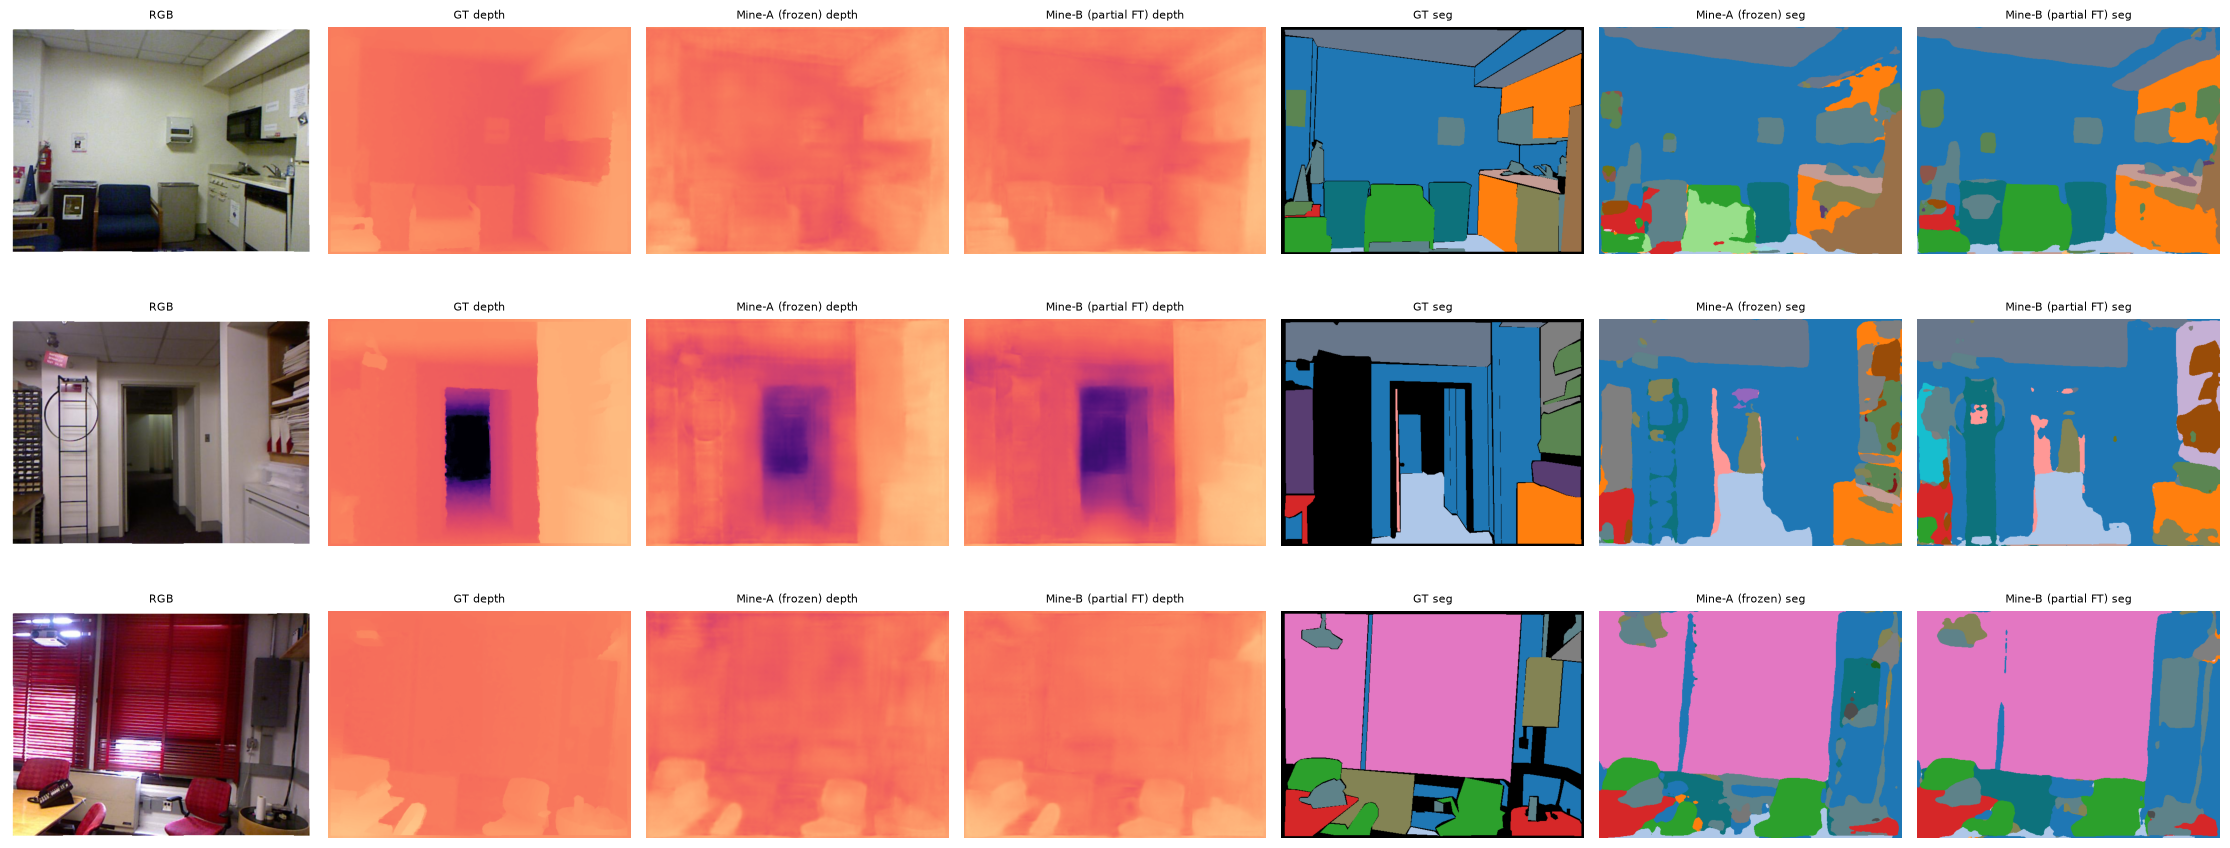

In [15]:
@torch.no_grad()
def show_qualitative(dataset: str, indices: Sequence[int] = (0, 7, 21)) -> None:
    """
    RGB, GT depth, depth of A and B, GT segmentation, segmentation of A and B for a few test images.
    """
    eval_dataset = make_dataset(dataset, CFG["datasets"][dataset]["eval_split"], train=False)

    models = {}
    for variant in CFG["variants"]:
        if (CFG["ckpt_root"] / run_name(dataset, variant) / "final.pt").exists():
            models[variant] = load_trained(dataset, variant)

    if not models:
        print("No trained models")
        return

    indices = [i for i in indices if i < len(eval_dataset)]
    max_depth = CFG["datasets"][dataset]["max_depth"]
    palette = PALETTES[dataset]

    n_cols = 2 + 2 * len(models) + 1
    fig, axs = plt.subplots(len(indices), n_cols, squeeze=False)
    fig.set_size_inches(3.2 * n_cols, 2.2 * len(indices) * (1 if dataset == "cityscapes" else 1.4))

    for row, i in enumerate(indices):
        sample = eval_dataset[i]
        gt_depth = sample["depth"].numpy()
        gt_seg = sample["seg"].numpy()

        # (title, image, is_depth)
        panels = [
            ("RGB", denormalize(sample["image"]), False),
            ("GT depth", np.where(gt_depth > 0, gt_depth, np.nan), True),
        ]

        predictions = {}
        for variant, model in models.items():
            depth, probs = predict(model, sample["image"][None].to(device))
            depth = F.interpolate(depth, size=gt_depth.shape, mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
            seg = F.interpolate(probs, size=gt_depth.shape, mode="bilinear", align_corners=False)[0].argmax(0).cpu().numpy()
            predictions[variant] = seg
            panels.append((f"{VARIANT_LABEL[variant]} depth", depth, True))

        panels.append(("GT seg", colorize_seg(gt_seg, palette), False))
        for variant, seg in predictions.items():
            panels.append((f"{VARIANT_LABEL[variant]} seg", colorize_seg(seg, palette), False))

        for col, (title, image, is_depth) in enumerate(panels):
            if is_depth:
                axs[row, col].imshow(image, cmap="magma_r", vmin=0, vmax=max_depth)
            else:
                axs[row, col].imshow(image)
            axs[row, col].set_title(title, fontsize=8)
            axs[row, col].axis("off")

    plt.tight_layout()
    fig.savefig(COMPARE_DIR / f"qualitative_{dataset}.png", dpi=110)
    plt.show()


show_qualitative("cityscapes")
show_qualitative("nyu")

### Variant A vs variant B

,A,B,Δ (B−A)
model,,,
cityscapes: cs_depth_full.rmse,5.693,5.453,-0.24
cityscapes: cs_depth_512x1024.abs_rel,0.1259,0.1221,-0.003794
cityscapes: cs_seg.mIoU,74.99,77.26,2.273
cityscapes: cs_seg_ms.mIoU,76.23,78.81,2.58
cityscapes: cs_depth_full_slide.rmse,5.279,4.893,-0.3865
cityscapes: cs_depth_512x1024_slide.abs_rel,0.1025,0.08927,-0.01323
cityscapes: cs_seg_slide.mIoU,76.13,79.21,3.082
cityscapes: trainable params (M),15.75,22.85,7.102
nyu: nyu_depth.rmse,0.4671,0.4329,-0.03421


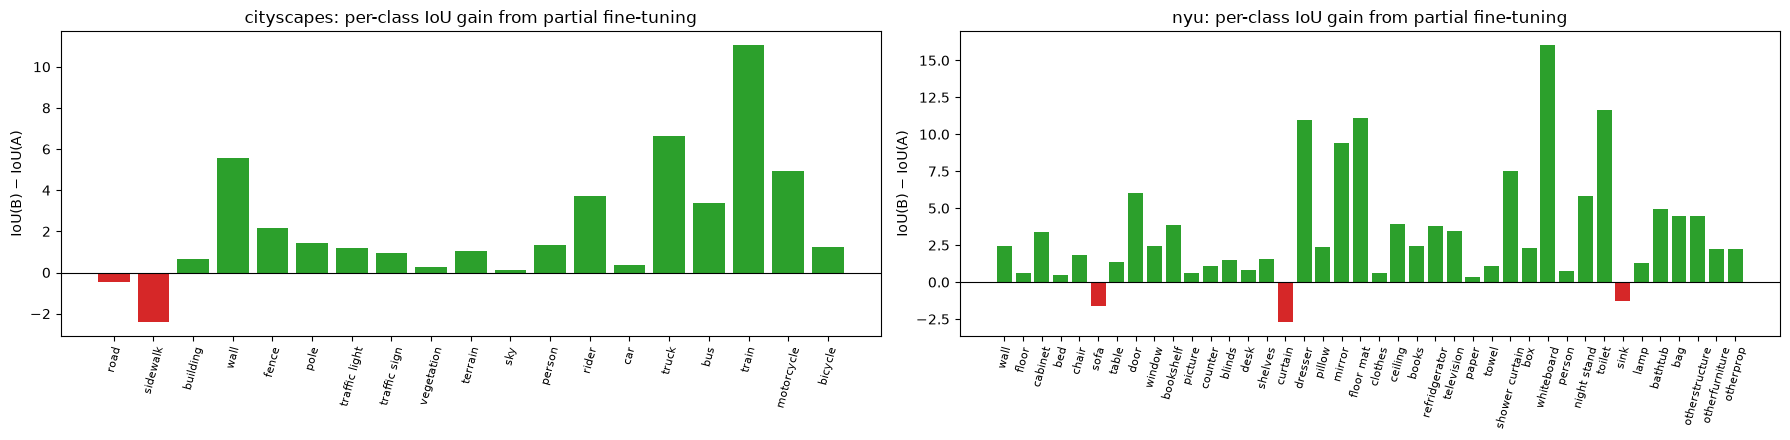

In [16]:
def compare_variants() -> None:
    """
    Summary table A vs B and per-class IoU gain of B over A.
    """
    protocol_metrics = {
        "cityscapes": [("cs_depth_full", "rmse"), ("cs_depth_512x1024", "abs_rel"), ("cs_seg", "mIoU"), ("cs_seg_ms", "mIoU"),
                       ("cs_depth_full_slide", "rmse"), ("cs_depth_512x1024_slide", "abs_rel"), ("cs_seg_slide", "mIoU")],
        "nyu": [("nyu_depth", "rmse"), ("nyu_depth", "abs_rel"), ("nyu_depth", "d1"), ("nyu_seg", "mIoU"),
                ("nyu_depth_slide", "rmse"), ("nyu_depth_slide", "abs_rel"), ("nyu_seg_slide", "mIoU")],
    }

    # summary table
    rows = []
    for dataset, metrics in protocol_metrics.items():
        results_a = mine(dataset, "frozen")
        results_b = mine(dataset, "partial_ft")
        if not (results_a and results_b):
            continue

        for protocol, metric in metrics:
            if protocol not in results_a or protocol not in results_b:
                continue
            value_a = results_a[protocol][metric]
            value_b = results_b[protocol][metric]
            rows.append({"model": f"{dataset}: {protocol}.{metric}", "A": value_a, "B": value_b, "Δ (B−A)": value_b - value_a})

        eff_a = EFF.get((dataset, "frozen"))
        eff_b = EFF.get((dataset, "partial_ft"))
        if eff_a and eff_b:
            rows.append({
                "model": f"{dataset}: trainable params (M)",
                "A": eff_a["trainable_M"],
                "B": eff_b["trainable_M"],
                "Δ (B−A)": eff_b["trainable_M"] - eff_a["trainable_M"],
            })

    if rows:
        show_table(rows, "variants_A_vs_B")

    # per-class IoU gain
    fig, axs = plt.subplots(1, 2)
    fig.set_size_inches(18, 4.5)

    for ax, (dataset, key, class_names) in zip(axs, [("cityscapes", "cs_seg", CS_NAMES[:19]), ("nyu", "nyu_seg", NYU40_NAMES)]):
        results_a = mine(dataset, "frozen")
        results_b = mine(dataset, "partial_ft")
        if not (results_a and results_b):
            continue

        deltas = []
        for iou_a, iou_b in zip(results_a[key]["per_class_iou"], results_b[key]["per_class_iou"]):
            if iou_a is None or iou_b is None:
                deltas.append(0)
            else:
                deltas.append(iou_b - iou_a)

        colors = ["tab:green" if delta >= 0 else "tab:red" for delta in deltas]
        ax.bar(range(len(class_names)), deltas, color=colors)
        ax.set_xticks(range(len(class_names)))
        ax.set_xticklabels(class_names, rotation=75, fontsize=8)
        ax.axhline(0, color="k", lw=0.8)
        ax.set_ylabel("IoU(B) − IoU(A)")
        ax.set_title(f"{dataset}: per-class IoU gain from partial fine-tuning")

    plt.tight_layout()
    fig.savefig(COMPARE_DIR / "variants_per_class.png", dpi=120)
    plt.show()


compare_variants()

---
## Final model vs the three papers (mean ± std over 3 seeds)

In [17]:
FINAL_CONFIG = load_json(ROOT / "results" / "final" / "config_final.json")
FINAL_SEEDS = [42, 43, 44]
NYU_FINAL = "no_frame_pe"
FINAL_TAG = "log" if FINAL_CONFIG["depth_param"] == "log" else "base"
FINAL_NAME = "Mine-Final"


def final_setup(dataset: str, seed: int) -> str:
    """configure() for one seed of the final model; returns the variant name to pass to run_name / load_trained."""
    if dataset == "nyu" and NYU_FINAL == "no_patch_mix":
        # notebook 12 runs = notebook 09 setup_final(..., frame_pe=False, photo_rng_fix=False, use_patch_mix=False)
        over = dict(use_critic=FINAL_CONFIG["use_critic"], seed=seed, frame_pe=False, photo_rng_fix=False, use_patch_mix=False,
                    depth_param=FINAL_CONFIG["depth_param"], scale_aug=tuple(FINAL_CONFIG["nyu_scale_aug"]), rotate_deg=FINAL_CONFIG["nyu_rotate_deg"])
        folder = f"nyu_{FINAL_TAG}-nofpe-nopatchmix_s{seed}"
        configure(ckpt_root=ROOT / "ckpt" / "final" / folder, results_root=ROOT / "results" / "final" / folder, **over)
        if FINAL_CONFIG.get("nyu_crop"):
            CFG["datasets"]["nyu"]["crop"] = tuple(FINAL_CONFIG["nyu_crop"])
        CFG["variants"]["final"] = dict(CFG["variants"]["partial_ft"], n_trainable_blocks=FINAL_CONFIG["blocks"])
        return "final"
    if dataset == "nyu" and NYU_FINAL == "no_frame_pe":
        configure(use_critic=False, seed=seed,
                  ckpt_root=ROOT / "ckpt" / "seeds" / f"nc8_s{seed}", results_root=ROOT / "results" / "seeds" / f"nc8_s{seed}")
        CFG["variants"]["partial_ft8"] = dict(CFG["variants"]["partial_ft"], n_trainable_blocks=8)
        return "partial_ft8"
    over = dict(use_critic=FINAL_CONFIG["use_critic"], seed=seed, frame_pe=FINAL_CONFIG["frame_pe"],
                photo_rng_fix=FINAL_CONFIG["photo_rng_fix"], depth_param=FINAL_CONFIG["depth_param"])
    if dataset == "nyu":
        over.update(scale_aug=tuple(FINAL_CONFIG["nyu_scale_aug"]), rotate_deg=FINAL_CONFIG["nyu_rotate_deg"])
    folder = f"{dataset}_{FINAL_TAG}_s{seed}"
    configure(ckpt_root=ROOT / "ckpt" / "final" / folder, results_root=ROOT / "results" / "final" / folder, **over)
    CFG["variants"]["final"] = dict(CFG["variants"]["partial_ft"], n_trainable_blocks=FINAL_CONFIG["blocks"])
    return "final"


FINAL_EVAL, FINAL_ZS = {}, {}
for dataset in ("cityscapes", "nyu"):
    for seed in FINAL_SEEDS:
        variant = final_setup(dataset, seed)
        print(f"{dataset} seed {seed}: {CFG['ckpt_root'] / run_name(dataset, variant)}")
        FINAL_EVAL[(dataset, seed)] = evaluate_run(dataset, variant)
        FINAL_ZS[(dataset, seed)] = zero_shot_run(dataset, variant)

# efficiency of the final architecture (the same for every seed)
variant = final_setup("cityscapes", 42)
model = build_model("cityscapes", variant, pretrained=False).to(device)
FINAL_EFF = efficiency(model, CFG["datasets"]["cityscapes"]["base_size"])
del model
torch.cuda.empty_cache()
configure()   # back to the default roots (A / B results)
save_json(FINAL_EFF, COMPARE_DIR / "final_efficiency.json")
print("NYU final model:", NYU_FINAL, "| efficiency:", {k: FINAL_EFF[k] for k in ("params_M", "GMACs")})


def fvals(dataset: str, key: str, metric: str, source: Optional[dict] = None) -> np.ndarray:
    """Values of one metric over the final seeds (missing seeds skipped)."""
    source = FINAL_EVAL if source is None else source
    out = []
    for seed in FINAL_SEEDS:
        res = source.get((dataset, seed)) or {}
        if key in res and metric in res[key]:
            out.append(res[key][metric])
    return np.array(out, dtype=float)


def pm(dataset: str, key: str, metric: str, source: Optional[dict] = None) -> Optional[str]:
    """'mean ± std' string over the final seeds, or None."""
    v = fvals(dataset, key, metric, source)
    if len(v) == 0:
        return None
    return f"{v.mean():.4g} ± {v.std(ddof=1):.2g}" if len(v) > 1 else f"{v.mean():.4g}"


def fmean(dataset: str, key: str, metric: str, source: Optional[dict] = None) -> Optional[float]:
    v = fvals(dataset, key, metric, source)
    return float(v.mean()) if len(v) else None


ABL_LABEL = {"frozen": "Mine-A (frozen) [ablation]", "partial_ft": "Mine-B (4 blocks + critic) [ablation]"}
FINAL_ROW = f"{FINAL_NAME} (mean ± std, {len(FINAL_SEEDS)} seeds)"

cityscapes seed 42: /home/chrisjf/Documents/ml4cv/ckpt/final/cityscapes_base_s42/cityscapes_final
cityscapes seed 43: /home/chrisjf/Documents/ml4cv/ckpt/final/cityscapes_base_s43/cityscapes_final
cityscapes seed 44: /home/chrisjf/Documents/ml4cv/ckpt/final/cityscapes_base_s44/cityscapes_final
nyu seed 42: /home/chrisjf/Documents/ml4cv/ckpt/seeds/nc8_s42/nyu_partial_ft8
nyu seed 43: /home/chrisjf/Documents/ml4cv/ckpt/seeds/nc8_s43/nyu_partial_ft8
nyu seed 44: /home/chrisjf/Documents/ml4cv/ckpt/seeds/nc8_s44/nyu_partial_ft8


NYU final model: no_frame_pe | efficiency: {'params_M': 37.806665, 'GMACs': 475.667838976}


### Final model vs SwinMTL (Tab. I, II, III, V)
Same tables and protocols as 'Mine vs SwinMTL': Tab. I is Cityscapes depth at 512×1024; Tab. II is Cityscapes at 1024×2048 (mIoU column: papers as reported, mine with the standard metric; SwinMTL's per-image metric shown for reference); Tab. III is NYUv2 with 40 classes; Tab. V is model size (FLOPs not comparable, see the caveat in 'Mine vs SwinMTL').

SwinMTL Tab. I: Cityscapes depth (* = self-supervised in the paper)


,source,res,abs_rel,sq_rel,rmse,rmse_log,d1,d2,d3
model,,,,,,,,,
GLNet,paper,1024x2048,0.111,—,6.437,0.182,0.868,0.961,0.983
Pilzer et al.*,paper,512x256,0.438,5.713,5.745,0.4,0.711,0.877,0.94
Struct2Depth*,paper,416x128,0.145,1.737,7.28,0.205,0.813,0.942,0.976
Li et al.*,paper,416x128,0.119,1.29,6.98,0.19,0.846,0.952,0.982
DynamicDepth*,paper,416x128,0.103,1,5.867,0.157,0.895,0.974,0.991
Lee et al.*,paper,832x256,0.116,1.213,6.695,0.186,0.852,0.951,0.982
InstaDM*,paper,832x256,0.111,1.158,6.437,0.182,0.868,0.961,0.983
SwinMTL,paper,512x1024,0.089,1.051,5.481,0.139,0.921,0.976,0.99
"Mine-Final (mean ± std, 3 seeds)",measured,512x1024,0.1082 ± 0.0021,0.8228 ± 0.0027,5.024 ± 0.019,0.1461 ± 0.00094,0.914 ± 0.00034,0.9815 ± 7.6e-05,0.9939 ± 6.9e-05


SwinMTL Tab. II: Cityscapes MTL at 1024x2048 (mIoU: standard 19-class metric for my models; SwinMTL per-image shown for reference)


,source,rmse,mIoU (paper: as reported; ours: standard),mIoU (ours: SwinMTL per-image)
model,,,,
Hybridnet,paper,12.09,66.61,—
MGMNet,paper,8.3,55.7,—
MTL,paper,6.797,70.43,—
PAD-Net,paper,6.777,70.23,—
3-ways,paper,6.528,75,—
[44],paper,6.649,74.95,—
SwinMTL,paper,6.352,76.41,—
"Mine-Final (mean ± std, 3 seeds)",measured,5.059 ± 0.019,77.74 ± 0.19,65.23 ± 0.017
"Mine-Final (mean ± std, 3 seeds) +slide (TTA)","measured, TTA",4.69 ± 0.008,78.98 ± 0.19,67.44 ± 0.064


SwinMTL Tab. III: NYUv2 MTL (40 classes; NYU final model = "no_frame_pe")


,source,rmse,mIoU (paper: as reported; ours: standard),mIoU (ours: SwinMTL per-image)
model,,,,
Cross-Stitch,paper,0.629,36.34,—
MTL,paper,0.638,39.44,—
PAD-Net,paper,0.627,36.61,—
3-ways,paper,0.622,39.47,—
[44],paper,0.604,38.93,—
MTAN,paper,0.5906,40.01,—
MTI-Net,paper,0.5365,45.97,—
ATRC,paper,0.5363,46.33,—
InvPT,paper,0.5183,53.56,—


SwinMTL Tab. V: model size (mine: GMACs at 512x1024; the input size of the paper FLOPs is not stated, so FLOPs are not comparable)


,source,"FLOPs (G, as reported)",params (M),trainable (M)
model,,,,
TaskPrompter,paper,416,373,—
ATRC w/ ViT-B,paper,260,119,—
PAD-Net w/ ViT-B,paper,166,109,—
SwinMTL w/ Swin-B,paper,65,87.38,—
Mine-Final (8 blocks),measured @ 512x1024,475.7,37.81,29.95
Mine-A (frozen) [ablation],measured @ 512x1024,475.7,37.81,15.75
Mine-B (4 blocks + critic) [ablation],measured @ 512x1024,475.7,37.81,22.85


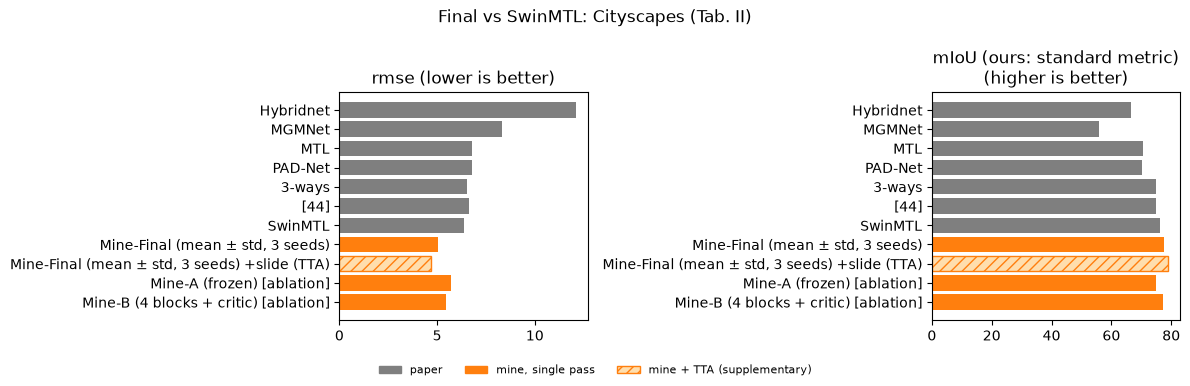

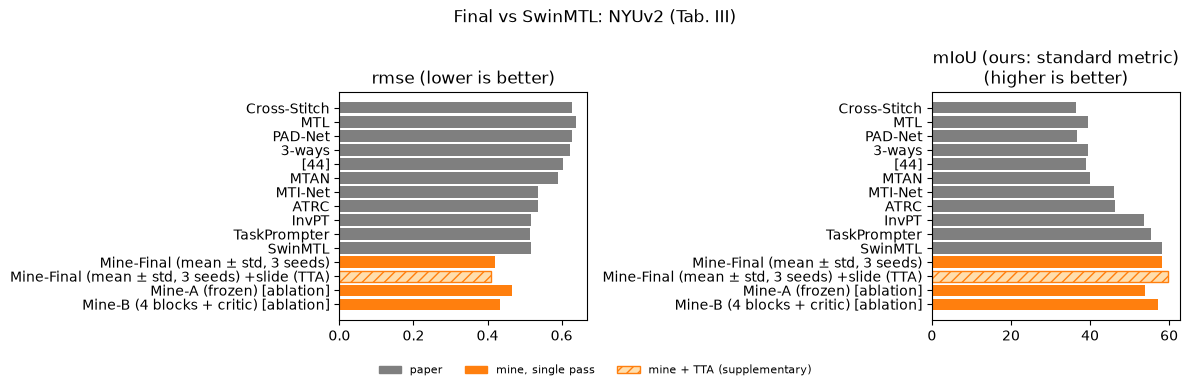

In [18]:
D_KEYS = ["abs_rel", "sq_rel", "rmse", "rmse_log", "d1", "d2", "d3"]

# Tab. I
rows = [dict(model=model, source="paper", **values) for model, values in PAPER["swinmtl_tab1"].items()]
for key, suffix, src in [("cs_depth_512x1024", "", "measured"), ("cs_depth_512x1024_slide", " +slide (TTA)", "measured, TTA")]:
    rows.append(dict(model=FINAL_ROW + suffix, source=src, res="512x1024", **{m: pm("cityscapes", key, m) for m in D_KEYS}))
for variant in CFG["variants"]:
    results = mine("cityscapes", variant, "cs_depth_512x1024")
    if results:
        rows.append(dict(model=ABL_LABEL[variant], source="measured, 1 seed", res="512x1024", **{m: results[m] for m in D_KEYS}))
print("SwinMTL Tab. I: Cityscapes depth (* = self-supervised in the paper)")
final_tab1 = show_table(rows, "final_vs_swinmtl_tab1", highlight=True)

# Tab. II
rows = [{"model": m, "source": "paper", "rmse": r, "mIoU (paper: as reported; ours: standard)": i, "mIoU (ours: SwinMTL per-image)": None} for m, (r, i) in PAPER["swinmtl_tab2"].items()]
rows.append({"model": FINAL_ROW, "source": "measured", "rmse": pm("cityscapes", "cs_depth_full", "rmse"),
             "mIoU (paper: as reported; ours: standard)": pm("cityscapes", "cs_seg", "mIoU"), "mIoU (ours: SwinMTL per-image)": pm("cityscapes", "cs_seg_swinmtl", "mIoU")})
rows.append({"model": FINAL_ROW + " +slide (TTA)", "source": "measured, TTA", "rmse": pm("cityscapes", "cs_depth_full_slide", "rmse"),
             "mIoU (paper: as reported; ours: standard)": pm("cityscapes", "cs_seg_slide", "mIoU"), "mIoU (ours: SwinMTL per-image)": pm("cityscapes", "cs_seg_swinmtl_slide", "mIoU")})
for variant in CFG["variants"]:
    results = mine("cityscapes", variant)
    if results:
        rows.append({"model": ABL_LABEL[variant], "source": "measured, 1 seed", "rmse": results["cs_depth_full"]["rmse"],
                     "mIoU (paper: as reported; ours: standard)": results["cs_seg"]["mIoU"], "mIoU (ours: SwinMTL per-image)": results["cs_seg_swinmtl"]["mIoU"]})
print('SwinMTL Tab. II: Cityscapes MTL at 1024x2048 (mIoU: standard 19-class metric for my models; SwinMTL per-image shown for reference)')
final_tab2 = show_table(rows, "final_vs_swinmtl_tab2", highlight=True)

# Tab. III
rows = [{"model": m, "source": "paper", "rmse": r, "mIoU (paper: as reported; ours: standard)": i, "mIoU (ours: SwinMTL per-image)": None} for m, (r, i) in PAPER["swinmtl_tab3"].items()]
rows.append({"model": FINAL_ROW, "source": "measured", "rmse": pm("nyu", "nyu_depth", "rmse"),
             "mIoU (paper: as reported; ours: standard)": pm("nyu", "nyu_seg", "mIoU"), "mIoU (ours: SwinMTL per-image)": pm("nyu", "nyu_seg_swinmtl", "mIoU")})
rows.append({"model": FINAL_ROW + " +slide (TTA)", "source": "measured, TTA", "rmse": pm("nyu", "nyu_depth_slide", "rmse"),
             "mIoU (paper: as reported; ours: standard)": pm("nyu", "nyu_seg_slide", "mIoU"), "mIoU (ours: SwinMTL per-image)": pm("nyu", "nyu_seg_swinmtl_slide", "mIoU")})
for variant in CFG["variants"]:
    results = mine("nyu", variant)
    if results:
        rows.append({"model": ABL_LABEL[variant], "source": "measured, 1 seed", "rmse": results["nyu_depth"]["rmse"],
                     "mIoU (paper: as reported; ours: standard)": results["nyu_seg"]["mIoU"], "mIoU (ours: SwinMTL per-image)": results["nyu_seg_swinmtl"]["mIoU"]})
print(f'SwinMTL Tab. III: NYUv2 MTL (40 classes; NYU final model = "{NYU_FINAL}")')
final_tab3 = show_table(rows, "final_vs_swinmtl_tab3", highlight=True)

# Tab. V
rows = [{"model": m, "source": "paper", "FLOPs (G, as reported)": f, "params (M)": p, "trainable (M)": None} for m, (f, p) in PAPER["swinmtl_tab5"].items()]
rows.append({"model": f"{FINAL_NAME} ({FINAL_CONFIG['blocks']} blocks)", "source": f"measured @ {FINAL_EFF['input']}",
             "FLOPs (G, as reported)": FINAL_EFF["GMACs"], "params (M)": FINAL_EFF["params_M"], "trainable (M)": FINAL_EFF.get("trainable_M")})
for variant in CFG["variants"]:
    eff = EFF.get(("cityscapes", variant))
    if eff:
        rows.append({"model": ABL_LABEL[variant], "source": f"measured @ {eff['input']}", "FLOPs (G, as reported)": eff["GMACs"],
                     "params (M)": eff["params_M"], "trainable (M)": eff.get("trainable_M")})
print('SwinMTL Tab. V: model size (mine: GMACs at 512x1024; the input size of the paper FLOPs is not stated, so FLOPs are not comparable)')
final_tab5 = show_table(rows, "final_vs_swinmtl_tab5", highlight=True)


def numeric(df: pd.DataFrame) -> pd.DataFrame:
    """Means of the 'mean ± std' strings, for the bar plots."""
    return df.apply(lambda col: col.map(lambda v: float(v.split(" ± ")[0]) if isinstance(v, str) and " ± " in v else v))


bar_compare(numeric(final_tab2), [("rmse", True), ("mIoU (paper: as reported; ours: standard)", False, "mIoU (ours: standard metric)")], "Final vs SwinMTL: Cityscapes (Tab. II)", "final_vs_swinmtl_cs")
bar_compare(numeric(final_tab3), [("rmse", True), ("mIoU (paper: as reported; ours: standard)", False, "mIoU (ours: standard metric)")], "Final vs SwinMTL: NYUv2 (Tab. III)", "final_vs_swinmtl_nyu")

### Final model vs DINOv2 (Tab. 10, 11) and DPT (Tab. 2)
Same protocols as 'Mine vs DINOv2 (single task, ViT-S/14)' and 'Mine vs DPT (single task)'. The DINOv2 table also has **D1** (`11_d1_dinov2_setup.ipynb`): DINOv2's own frozen ViT-S/14 + DPT depth setup, trained on my 795 NYU images. It isolates the training-data gap (795 images here; ≈ 24k frames for DINOv2; DPT-Hybrid is depth-pretrained on ≈ 1.4 M images and fine-tuned on NYUv2). The final model also fine-tunes its last 8 ViT blocks, while DINOv2's backbone is frozen, so D1 (frozen) is the like-for-like row.

DINOv2 Tab. 11: NYUv2 depth, RMSE


,source,NYU RMSE,"NYU RMSE (flip, TTA)","NYU RMSE (slide, TTA)"
model,,,,
DINOv2 ViT-S/14 lin. 1,"paper (Tab. 11), ≈ 24k frames",0.449,—,—
DINOv2 ViT-S/14 lin. 4,"paper (Tab. 11), ≈ 24k frames",0.417,—,—
DINOv2 ViT-S/14 DPT,"paper (Tab. 11), ≈ 24k frames",0.356,—,—
"Mine-Final (mean ± std, 3 seeds)","measured, 795 images",0.4197 ± 0.0013,0.4136 ± 0.0013,0.4096 ± 0.00084
"Mine-D1 (DINOv2 setup: frozen + DPT, depth only) [ablation]","measured, 795 images, 1 seed",0.4199,0.4146,0.4144
Mine-A (frozen) [ablation],"measured, 795 images, 1 seed",0.4671,0.4597,0.4537
Mine-B (4 blocks + critic) [ablation],"measured, 795 images, 1 seed",0.4329,0.4255,0.4208


DINOv2 Tab. 10: Cityscapes segmentation, mIoU (19 classes)


,source,CS mIoU (single-scale / lin.),CS mIoU (+ms),"CS mIoU (slide, TTA)"
model,,,,
DINOv2 ViT-S/14,paper (Tab. 10),66.6,77.1,—
"Mine-Final (mean ± std, 3 seeds)",measured,77.74 ± 0.19,79.79 ± 0.13,78.98 ± 0.19
Mine-A (frozen) [ablation],"measured, 1 seed",74.99,76.23,76.13
Mine-B (4 blocks + critic) [ablation],"measured, 1 seed",77.26,78.81,79.21


DPT Tab. 2: NYUv2 depth


,source,d1,d2,d3,abs_rel,rmse,log10
model,,,,,,,
DORN,"paper (Tab. 2), ≈ 24k frames",0.828,0.965,0.992,0.115,0.509,0.051
VNL,"paper (Tab. 2), ≈ 24k frames",0.875,0.976,0.994,0.111,0.416,0.048
BTS,"paper (Tab. 2), ≈ 24k frames",0.885,0.978,0.994,0.11,0.392,0.047
DPT-Hybrid,"paper (Tab. 2), ≈ 24k frames",0.904,0.988,0.998,0.11,0.357,0.045
"Mine-Final (mean ± std, 3 seeds)",measured,0.8652 ± 0.0014,0.9833 ± 0.00068,0.9971 ± 2e-05,0.1204 ± 0.00096,0.4197 ± 0.0013,0.0505 ± 0.00033
"Mine-Final (mean ± std, 3 seeds) +flip (TTA)","measured, TTA",0.8686 ± 0.001,0.984 ± 0.00071,0.9972 ± 8.5e-05,0.1186 ± 0.00092,0.4136 ± 0.0013,0.04978 ± 0.00031
"Mine-Final (mean ± std, 3 seeds) +slide (TTA)","measured, TTA",0.8736 ± 0.00056,0.9848 ± 0.00058,0.9973 ± 8.7e-05,0.1159 ± 0.00057,0.4096 ± 0.00084,0.04905 ± 0.00022
Mine-A (frozen) [ablation],"measured, 1 seed",0.8323,0.976,0.9965,0.1373,0.4671,0.05664
Mine-B (4 blocks + critic) [ablation],"measured, 1 seed",0.857,0.9823,0.997,0.1247,0.4329,0.05209


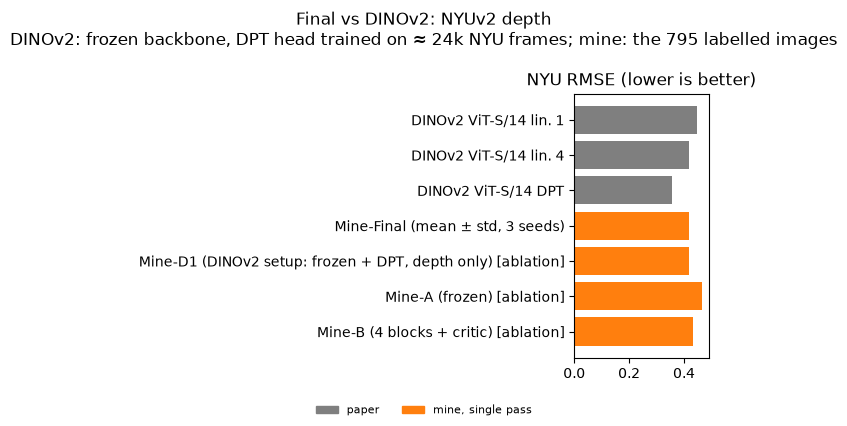

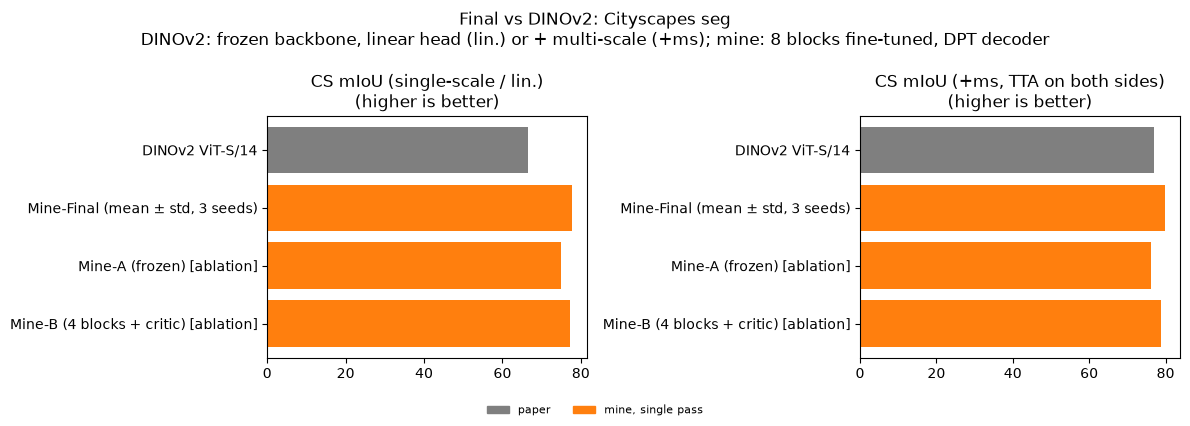

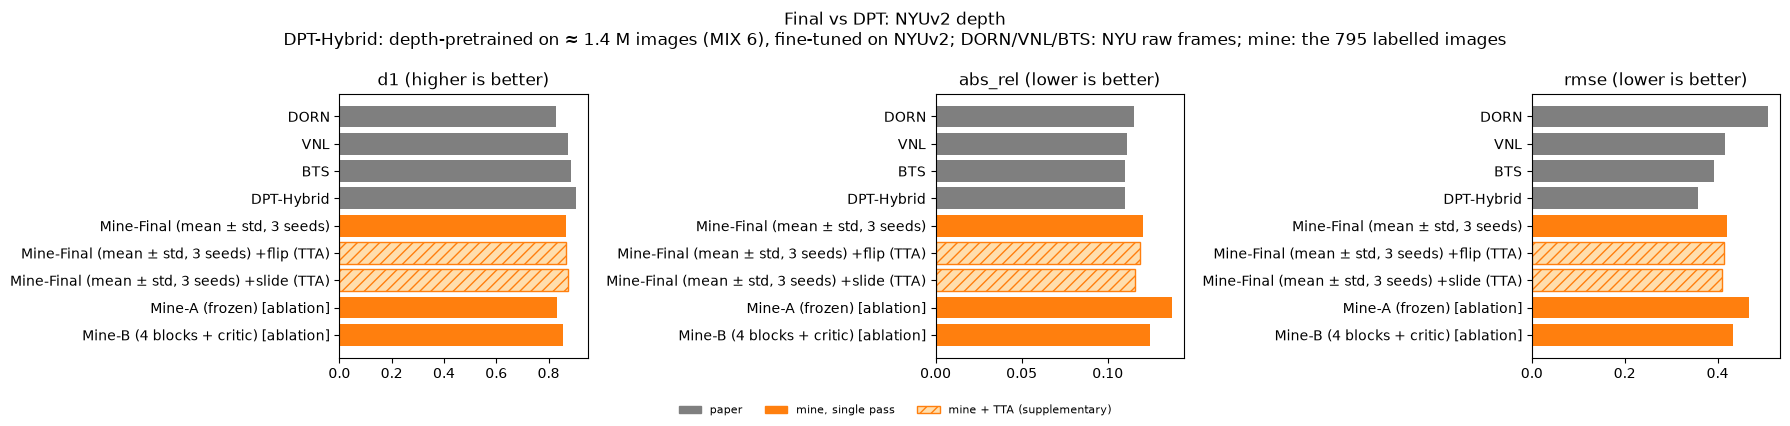

In [19]:
dd, ds_ = PAPER["dinov2_tab11_vits14"], PAPER["dinov2_tab10_vits14"]
R_D1 = load_json(ROOT / "results" / "d1" / "eval" / "nyu_frozen.json")

# NYUv2 depth (Tab. 11)
rows = [{"model": f"DINOv2 ViT-S/14 {s}", "source": "paper (Tab. 11), ≈ 24k frames", "NYU RMSE": dd["nyu"][i]} for i, s in enumerate(["lin. 1", "lin. 4", "DPT"])]
rows.append({"model": FINAL_ROW, "source": "measured, 795 images", "NYU RMSE": pm("nyu", "nyu_depth", "rmse"),
             "NYU RMSE (flip, TTA)": pm("nyu", "nyu_depth_flip", "rmse"), "NYU RMSE (slide, TTA)": pm("nyu", "nyu_depth_slide", "rmse")})
if R_D1:
    rows.append({"model": "Mine-D1 (DINOv2 setup: frozen + DPT, depth only) [ablation]", "source": "measured, 795 images, 1 seed",
                 "NYU RMSE": R_D1["nyu_depth"]["rmse"], "NYU RMSE (flip, TTA)": R_D1["nyu_depth_flip"]["rmse"],
                 "NYU RMSE (slide, TTA)": R_D1.get("nyu_depth_slide", {}).get("rmse")})
for variant in CFG["variants"]:
    results = mine("nyu", variant)
    if results:
        rows.append({"model": ABL_LABEL[variant], "source": "measured, 795 images, 1 seed", "NYU RMSE": results["nyu_depth"]["rmse"],
                     "NYU RMSE (flip, TTA)": results["nyu_depth_flip"]["rmse"], "NYU RMSE (slide, TTA)": results.get("nyu_depth_slide", {}).get("rmse")})
print("DINOv2 Tab. 11: NYUv2 depth, RMSE")
final_dino_depth = show_table(rows, "final_vs_dinov2_nyu_depth", highlight=True)

# Cityscapes segmentation (Tab. 10)
rows = [{"model": "DINOv2 ViT-S/14", "source": "paper (Tab. 10)", "CS mIoU (single-scale / lin.)": ds_["cityscapes"][0], "CS mIoU (+ms)": ds_["cityscapes"][1]}]
rows.append({"model": FINAL_ROW, "source": "measured", "CS mIoU (single-scale / lin.)": pm("cityscapes", "cs_seg", "mIoU"),
             "CS mIoU (+ms)": pm("cityscapes", "cs_seg_ms", "mIoU"), "CS mIoU (slide, TTA)": pm("cityscapes", "cs_seg_slide", "mIoU")})
for variant in CFG["variants"]:
    results = mine("cityscapes", variant)
    if results:
        rows.append({"model": ABL_LABEL[variant], "source": "measured, 1 seed", "CS mIoU (single-scale / lin.)": results["cs_seg"]["mIoU"],
                     "CS mIoU (+ms)": results["cs_seg_ms"]["mIoU"], "CS mIoU (slide, TTA)": results.get("cs_seg_slide", {}).get("mIoU")})
print("DINOv2 Tab. 10: Cityscapes segmentation, mIoU (19 classes)")
final_dino_seg = show_table(rows, "final_vs_dinov2_cs_seg", highlight=True)

# DPT Tab. 2
DPT_KEYS = ["d1", "d2", "d3", "abs_rel", "rmse", "log10"]
rows = [dict(model=m, source="paper (Tab. 2), ≈ 24k frames", **v) for m, v in PAPER["dpt_tab2"].items()]
for key, suffix, src in [("nyu_depth", "", "measured"), ("nyu_depth_flip", " +flip (TTA)", "measured, TTA"), ("nyu_depth_slide", " +slide (TTA)", "measured, TTA")]:
    rows.append(dict(model=FINAL_ROW + suffix, source=src, **{m: pm("nyu", key, m) for m in DPT_KEYS}))
for variant in CFG["variants"]:
    results = mine("nyu", variant)
    if results:
        rows.append(dict(model=ABL_LABEL[variant], source="measured, 1 seed", **{m: results["nyu_depth"][m] for m in DPT_KEYS}))
print("DPT Tab. 2: NYUv2 depth")
final_dpt = show_table(rows, "final_vs_dpt_nyu", highlight=True)

bar_compare(numeric(final_dino_depth), [("NYU RMSE", True)], "Final vs DINOv2: NYUv2 depth", "final_vs_dinov2_nyu", note="DINOv2: frozen backbone, DPT head trained on ≈ 24k NYU frames; mine: the 795 labelled images")
bar_compare(numeric(final_dino_seg), [("CS mIoU (single-scale / lin.)", False), ("CS mIoU (+ms)", False, "CS mIoU (+ms, TTA on both sides)")], "Final vs DINOv2: Cityscapes seg", "final_vs_dinov2_cs", note="DINOv2: frozen backbone, linear head (lin.) or + multi-scale (+ms); mine: 8 blocks fine-tuned, DPT decoder")
bar_compare(numeric(final_dpt), [("d1", False), ("abs_rel", True), ("rmse", True)], "Final vs DPT: NYUv2 depth", "final_vs_dpt_nyu", note="DPT-Hybrid: depth-pretrained on ≈ 1.4 M images (MIX 6), fine-tuned on NYUv2; DORN/VNL/BTS: NYU raw frames; mine: the 795 labelled images")

### Zero-shot transfer of the final model (KITTI, SUN RGB-D, class subsets)
Same protocols as 'Zero-shot runners', mean ± std over the 3 seeds. These are extras: apart from DINOv2's NYU→SUN transfer (Tab. 11), none of the three papers trains on Cityscapes / NYUv2 and tests on these sets, so the other paper rows are in-domain or other-setting references (tags in the `source` column).

In [20]:
# KITTI (Cityscapes model)
rows = [dict(model=m, source="paper, in-domain (DPT Tab. 3)", **v) for m, v in PAPER["dpt_tab3"].items()]
rows.append(dict(model="DINOv2 ViT-S/14 DPT", source="paper, in-domain (Tab. 11)", rmse=PAPER["dinov2_tab11_vits14"]["kitti"][2]))
for key, tag in [("kitti_raw", "zero-shot raw"), ("kitti_median", "zero-shot median-scaled")]:
    rows.append(dict(model=f"{FINAL_ROW} ({tag})", source="measured", **{m: pm("cityscapes", key, m, FINAL_ZS) for m in ["d1", "d2", "d3", "abs_rel", "rmse", "rmse_log"]}))
for variant in CFG["variants"]:
    for key, tag in [("kitti_raw", "zero-shot raw"), ("kitti_median", "zero-shot median-scaled")]:
        zs = ZS.get(("cityscapes", variant), {}).get(key)
        if zs:
            rows.append(dict(model=f"{ABL_LABEL[variant]} ({tag})", source="measured, 1 seed", **{m: zs[m] for m in ["d1", "d2", "d3", "abs_rel", "rmse", "rmse_log"]}))
print("KITTI Eigen test (652), Cityscapes model zero-shot")
show_table(rows, "final_kitti_zeroshot", highlight=True)

# SUN RGB-D (NYU model)
rows = [dict(model=f"DINOv2 ViT-S/14 {s}", source="paper, NYU->SUN (Tab. 11)", rmse=r) for s, r in zip(["lin. 1", "lin. 4", "DPT"], PAPER["dinov2_tab11_vits14"]["sun"])]
for key, tag in [("sun_raw", "NYU->SUN raw"), ("sun_median", "NYU->SUN median-scaled")]:
    rows.append(dict(model=f"{FINAL_ROW} ({tag})", source="measured", **{m: pm("nyu", key, m, FINAL_ZS) for m in ["d1", "abs_rel", "rmse", "rmse_log"]}))
for variant in CFG["variants"]:
    for key, tag in [("sun_raw", "NYU->SUN raw"), ("sun_median", "NYU->SUN median-scaled")]:
        zs = ZS.get(("nyu", variant), {}).get(key)
        if zs:
            rows.append(dict(model=f"{ABL_LABEL[variant]} ({tag})", source="measured, 1 seed", **{m: zs[m] for m in ["d1", "abs_rel", "rmse", "rmse_log"]}))
print("SUN RGB-D test (NYUdata scenes excluded)")
show_table(rows, "final_sun_zeroshot", highlight=True)

# segmentation on the mapped class subsets
rows = []
for dataset in ("cityscapes", "nyu"):
    for target in ("ade20k", "voc2012", "pcontext"):
        key = f"{target}_subset"
        n_cls = next((FINAL_ZS[(dataset, s)][key]["n_classes"] for s in FINAL_SEEDS if key in (FINAL_ZS.get((dataset, s)) or {})), None)
        if n_cls is not None:
            rows.append(dict(model=f"{FINAL_ROW} [{dataset}->{target}]", source="zero-shot subset", n_classes=n_cls,
                             mIoU=pm(dataset, key, "mIoU", FINAL_ZS), pixAcc=pm(dataset, key, "pixAcc", FINAL_ZS)))
        for variant in CFG["variants"]:
            zs = ZS.get((dataset, variant), {}).get(key)
            if zs:
                rows.append(dict(model=f"{ABL_LABEL[variant]} [{dataset}->{target}]", source="zero-shot subset, 1 seed",
                                 n_classes=zs["n_classes"], mIoU=zs["mIoU"], pixAcc=zs["pixAcc"]))
print("Zero-shot segmentation over the mapped class subsets")
show_table(rows, "final_seg_zeroshot", highlight=True)

KITTI Eigen test (652), Cityscapes model zero-shot


,source,d1,d2,d3,abs_rel,rmse,rmse_log
model,,,,,,,
DORN,"paper, in-domain (DPT Tab. 3)",0.932,0.984,0.994,0.072,2.626,0.12
VNL,"paper, in-domain (DPT Tab. 3)",0.938,0.99,0.998,0.072,3.258,0.117
BTS,"paper, in-domain (DPT Tab. 3)",0.956,0.993,0.998,0.059,2.756,0.096
DPT-Hybrid,"paper, in-domain (DPT Tab. 3)",0.959,0.995,0.999,0.062,2.573,0.092
DINOv2 ViT-S/14 DPT,"paper, in-domain (Tab. 11)",—,—,—,—,2.34,—
"Mine-Final (mean ± std, 3 seeds) (zero-shot raw)",measured,0.7682 ± 0.014,0.9811 ± 0.0016,0.9964 ± 0.00036,0.1511 ± 0.0012,3.34 ± 0.026,0.1883 ± 0.0017
"Mine-Final (mean ± std, 3 seeds) (zero-shot median-scaled)",measured,0.8951 ± 0.0046,0.9851 ± 0.00056,0.9969 ± 0.00011,0.1118 ± 0.0035,4.096 ± 0.076,0.1438 ± 0.0032
Mine-A (frozen) [ablation] (zero-shot raw),"measured, 1 seed",0.8647,0.9797,0.9958,0.122,3.769,0.1584
Mine-A (frozen) [ablation] (zero-shot median-scaled),"measured, 1 seed",0.8838,0.9845,0.9969,0.1144,3.779,0.1485


SUN RGB-D test (NYUdata scenes excluded)


,source,rmse,d1,abs_rel,rmse_log
model,,,,,
DINOv2 ViT-S/14 lin. 1,"paper, NYU->SUN (Tab. 11)",0.477,—,—,—
DINOv2 ViT-S/14 lin. 4,"paper, NYU->SUN (Tab. 11)",0.431,—,—,—
DINOv2 ViT-S/14 DPT,"paper, NYU->SUN (Tab. 11)",0.409,—,—,—
"Mine-Final (mean ± std, 3 seeds) (NYU->SUN raw)",measured,0.6075 ± 0.0015,0.7531 ± 0.0012,0.2122 ± 0.0011,0.2437 ± 0.00042
"Mine-Final (mean ± std, 3 seeds) (NYU->SUN median-scaled)",measured,0.5149 ± 0.0019,0.8412 ± 0.00063,0.1662 ± 0.00086,0.207 ± 0.0005
Mine-A (frozen) [ablation] (NYU->SUN raw),"measured, 1 seed",0.6299,0.7235,0.2265,0.2559
Mine-A (frozen) [ablation] (NYU->SUN median-scaled),"measured, 1 seed",0.5396,0.8125,0.1761,0.2185
Mine-B (4 blocks + critic) [ablation] (NYU->SUN raw),"measured, 1 seed",0.6113,0.7483,0.2146,0.2458
Mine-B (4 blocks + critic) [ablation] (NYU->SUN median-scaled),"measured, 1 seed",0.519,0.8358,0.1679,0.209


Zero-shot segmentation over the mapped class subsets


,source,n_classes,mIoU,pixAcc
model,,,,
"Mine-Final (mean ± std, 3 seeds) [cityscapes->ade20k]",zero-shot subset,15,59 ± 0.73,86.86 ± 0.3
Mine-A (frozen) [ablation] [cityscapes->ade20k],"zero-shot subset, 1 seed",15,57.75,86.99
Mine-B (4 blocks + critic) [ablation] [cityscapes->ade20k],"zero-shot subset, 1 seed",15,60.94,87.5
"Mine-Final (mean ± std, 3 seeds) [cityscapes->voc2012]",zero-shot subset,7,70.02 ± 1.8,96.4 ± 0.36
Mine-A (frozen) [ablation] [cityscapes->voc2012],"zero-shot subset, 1 seed",7,68.65,95.97
Mine-B (4 blocks + critic) [ablation] [cityscapes->voc2012],"zero-shot subset, 1 seed",7,70.12,96.42
"Mine-Final (mean ± std, 3 seeds) [cityscapes->pcontext]",zero-shot subset,14,56.58 ± 1.3,79.81 ± 1.3
Mine-A (frozen) [ablation] [cityscapes->pcontext],"zero-shot subset, 1 seed",14,54.05,75.32
Mine-B (4 blocks + critic) [ablation] [cityscapes->pcontext],"zero-shot subset, 1 seed",14,58.32,81.66


,source,n_classes,mIoU,pixAcc
model,,,,
"Mine-Final (mean ± std, 3 seeds) [cityscapes->ade20k]",zero-shot subset,15,59 ± 0.73,86.86 ± 0.3
Mine-A (frozen) [ablation] [cityscapes->ade20k],"zero-shot subset, 1 seed",15,57.75431,86.989864
Mine-B (4 blocks + critic) [ablation] [cityscapes->ade20k],"zero-shot subset, 1 seed",15,60.939397,87.496355
"Mine-Final (mean ± std, 3 seeds) [cityscapes->voc2012]",zero-shot subset,7,70.02 ± 1.8,96.4 ± 0.36
Mine-A (frozen) [ablation] [cityscapes->voc2012],"zero-shot subset, 1 seed",7,68.649425,95.967133
Mine-B (4 blocks + critic) [ablation] [cityscapes->voc2012],"zero-shot subset, 1 seed",7,70.123848,96.424091
"Mine-Final (mean ± std, 3 seeds) [cityscapes->pcontext]",zero-shot subset,14,56.58 ± 1.3,79.81 ± 1.3
Mine-A (frozen) [ablation] [cityscapes->pcontext],"zero-shot subset, 1 seed",14,54.048887,75.324462
Mine-B (4 blocks + critic) [ablation] [cityscapes->pcontext],"zero-shot subset, 1 seed",14,58.324517,81.662381


### Master table with the final model, and targets
The all-in-one table with the final model added: means over 3 seeds, the std is in `results/compare/final_targets.csv`. A and B are kept as ablation rows. The target check asks, for each paper number i set out to beat, whether the mean beats it and how many of the 3 seeds do.

,CS AbsRel,CS RMSE,CS mIoU,NYU RMSE,NYU AbsRel,NYU δ1,NYU mIoU,KITTI RMSE,KITTI AbsRel,SUN RMSE,ADE20K mIoU,VOC mIoU,PC mIoU,Params (M),GMACs
SwinMTL (Swin-V2-B),0.089 (paper),6.352 (paper),76.41 (paper),0.5179 (paper),—,—,58.14 (paper),—,—,—,—,—,—,87.38 (paper),"65 (paper; input size not stated, not comparable)"
DINOv2 ViT-S/14 (frozen),—,—,66.6 (paper),0.356 (paper),—,—,—,2.34 (paper),—,"0.409 (paper, NYU→SUN zero-shot)",44.3 (paper),81.1 (paper),—,"22.1 (model code; backbone only, not comparable)",—
DPT-Hybrid,—,—,—,0.357 (paper),0.11 (paper),0.904 (paper),—,2.573 (paper),0.062 (paper),—,49.02 (paper),—,60.46 (paper),123 (paper),—
DPT-Large,—,—,—,—,—,—,—,—,—,—,47.63 (paper),—,—,343 (paper),—
Mine-A (frozen),0.1259 (measured),5.693 (measured),74.99 (measured),0.4671 (measured),0.1373 (measured),0.8323 (measured),53.88 (measured),3.769 (zero-shot),0.122 (zero-shot),0.6299 (zero-shot),"57.75 (zero-shot, CS model, 15 cls)","68.65 (zero-shot, CS model, 7 cls)","54.05 (zero-shot, CS model, 14 cls)",37.81 (measured),475.7 (measured @512x1024)
Mine-B (partial FT),0.1221 (measured),5.453 (measured),77.26 (measured),0.4329 (measured),0.1247 (measured),0.857 (measured),57.27 (measured),3.951 (zero-shot),0.1249 (zero-shot),0.6113 (zero-shot),"60.94 (zero-shot, CS model, 15 cls)","70.12 (zero-shot, CS model, 7 cls)","58.32 (zero-shot, CS model, 14 cls)",37.81 (measured),475.7 (measured @512x1024)
Mine-A (frozen) +slide (TTA),"0.1025 (measured, TTA)","5.279 (measured, TTA)","76.13 (measured, TTA)","0.4537 (measured, TTA)","0.1319 (measured, TTA)","0.8411 (measured, TTA)","54.79 (measured, TTA)",—,—,—,—,—,—,—,—
Mine-B (partial FT) +slide (TTA),"0.08927 (measured, TTA)","4.893 (measured, TTA)","79.21 (measured, TTA)","0.4208 (measured, TTA)","0.1197 (measured, TTA)","0.8657 (measured, TTA)","59 (measured, TTA)",—,—,—,—,—,—,—,—
Mine-Final (mean of 3 seeds),"0.1082 (measured, mean of 3)","5.059 (measured, mean of 3)","77.74 (measured, mean of 3)","0.4197 (measured, mean of 3)","0.1204 (measured, mean of 3)","0.8652 (measured, mean of 3)","58.1 (measured, mean of 3)","3.34 (zero-shot, mean of 3)","0.1511 (zero-shot, mean of 3)","0.6075 (zero-shot, mean of 3)","59 (zero-shot, CS model, mean of 3)","70.02 (zero-shot, CS model, mean of 3)","56.58 (zero-shot, CS model, mean of 3)",37.81 (measured),475.7 (measured @512x1024)
Mine-Final +slide (TTA),"0.08281 (measured, TTA)","4.69 (measured, TTA)","78.98 (measured, TTA)","0.4096 (measured, TTA)","0.1159 (measured, TTA)","0.8736 (measured, TTA)","59.76 (measured, TTA)",—,—,—,—,—,—,—,—


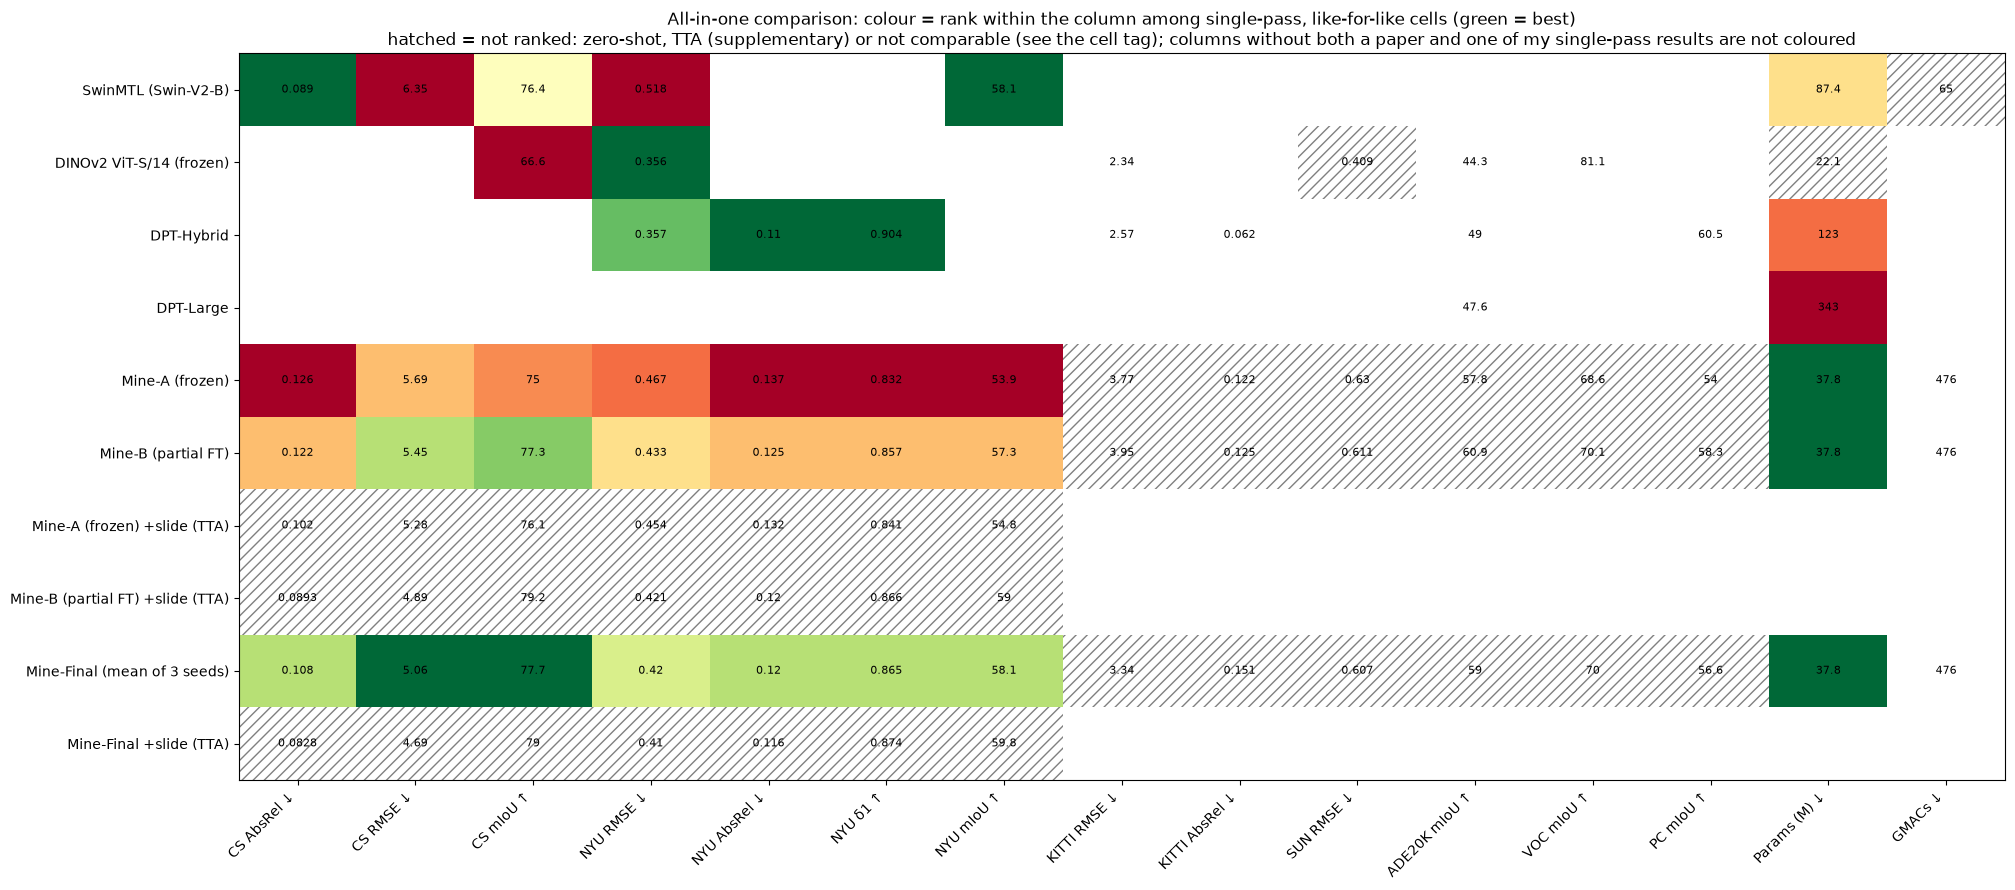

,paper,mean,std,beats,seeds_beating
target,,,,,
CS AbsRel vs SwinMTL,0.0890,0.1082,0.0021,False,0/3
CS SqRel vs SwinMTL,1.0510,0.8228,0.0027,True,3/3
CS RMSE (512) vs SwinMTL,5.4810,5.0244,0.0192,True,3/3
CS RMSElog vs SwinMTL,0.1390,0.1461,0.0009,False,0/3
CS δ1 vs SwinMTL,0.9210,0.9140,0.0003,False,0/3
CS RMSE (full) vs SwinMTL,6.3520,5.0591,0.0189,True,3/3
CS mIoU (standard) vs SwinMTL,76.4100,77.7365,0.1863,True,3/3
CS mIoU (SwinMTL per-image) vs SwinMTL,76.4100,65.2273,0.0170,False,0/3
"CS mIoU vs DINOv2 (frozen, lin.)",66.6000,77.7365,0.1863,True,3/3


NYU final model: no_frame_pe


In [21]:
MASTER = build_master()
final_cells = {}
for col, (ds, key, metric) in {
    "CS AbsRel": ("cityscapes", "cs_depth_512x1024", "abs_rel"), "CS RMSE": ("cityscapes", "cs_depth_full", "rmse"),
    "CS mIoU": ("cityscapes", "cs_seg", "mIoU"), "NYU RMSE": ("nyu", "nyu_depth", "rmse"), "NYU AbsRel": ("nyu", "nyu_depth", "abs_rel"),
    "NYU δ1": ("nyu", "nyu_depth", "d1"), "NYU mIoU": ("nyu", "nyu_seg", "mIoU"),
}.items():
    v = fmean(ds, key, metric)
    if v is not None:
        final_cells[col] = (v, "measured, mean of 3")
for col, (ds, key, metric) in {"KITTI RMSE": ("cityscapes", "kitti_raw", "rmse"), "KITTI AbsRel": ("cityscapes", "kitti_raw", "abs_rel"),
                               "SUN RMSE": ("nyu", "sun_raw", "rmse")}.items():
    v = fmean(ds, key, metric, FINAL_ZS)
    if v is not None:
        final_cells[col] = (v, "zero-shot, mean of 3")
for col, key in [("ADE20K mIoU", "ade20k_subset"), ("VOC mIoU", "voc2012_subset"), ("PC mIoU", "pcontext_subset")]:
    cands = [(src, fmean(ds, key, "mIoU", FINAL_ZS)) for src, ds in (("CS", "cityscapes"), ("NYU", "nyu"))]
    cands = [c for c in cands if c[1] is not None]
    if cands:
        src, v = max(cands, key=lambda c: c[1])
        final_cells[col] = (v, f"zero-shot, {src} model, mean of 3")
final_cells["Params (M)"] = (FINAL_EFF["params_M"], "measured")
final_cells["GMACs"] = (FINAL_EFF["GMACs"], "measured @512x1024")
MASTER[f"{FINAL_NAME} (mean of {len(FINAL_SEEDS)} seeds)"] = final_cells
MASTER[f"{FINAL_NAME} +slide (TTA)"] = {
    col: (fmean(ds, key, m), "measured, TTA") for col, (ds, key, m) in {
        "CS AbsRel": ("cityscapes", "cs_depth_512x1024_slide", "abs_rel"), "CS RMSE": ("cityscapes", "cs_depth_full_slide", "rmse"),
        "CS mIoU": ("cityscapes", "cs_seg_slide", "mIoU"), "NYU RMSE": ("nyu", "nyu_depth_slide", "rmse"),
        "NYU AbsRel": ("nyu", "nyu_depth_slide", "abs_rel"), "NYU δ1": ("nyu", "nyu_depth_slide", "d1"), "NYU mIoU": ("nyu", "nyu_seg_slide", "mIoU"),
    }.items() if fmean(ds, key, m) is not None}
show_master(MASTER)   # overwrites master_table.csv / master_heatmap.png with the final model included

# targets: does the mean, and does every seed, beat each paper number? (single pass)
TARGETS = FINAL_TARGETS   # defined once in repro_common.py
rows = []
for label, ds, key, metric, paper, lower in TARGETS:
    v = fvals(ds, key, metric)
    beats = (v < paper) if lower else (v > paper)
    rows.append(dict(target=label, paper=paper, mean=v.mean(), std=v.std(ddof=1), beats=bool((v.mean() < paper) if lower else (v.mean() > paper)),
                     seeds_beating=f"{int(beats.sum())}/{len(v)}"))
final_targets = pd.DataFrame(rows).set_index("target")
final_targets.to_csv(COMPARE_DIR / "final_targets.csv")
display(final_targets.style.format(precision=4).apply(lambda r: ["background-color: rgba(0,180,0,.2)" if r["beats"] else "background-color: rgba(220,0,0,.15)"] * len(r), axis=1))
print(f"NYU final model: {NYU_FINAL}")

### Qualitative results: final model vs B
The same three test images per dataset. Shown: RGB, GT depth, depth of B and of the final model (seed 42), GT segmentation, and segmentation of B and of the final model.

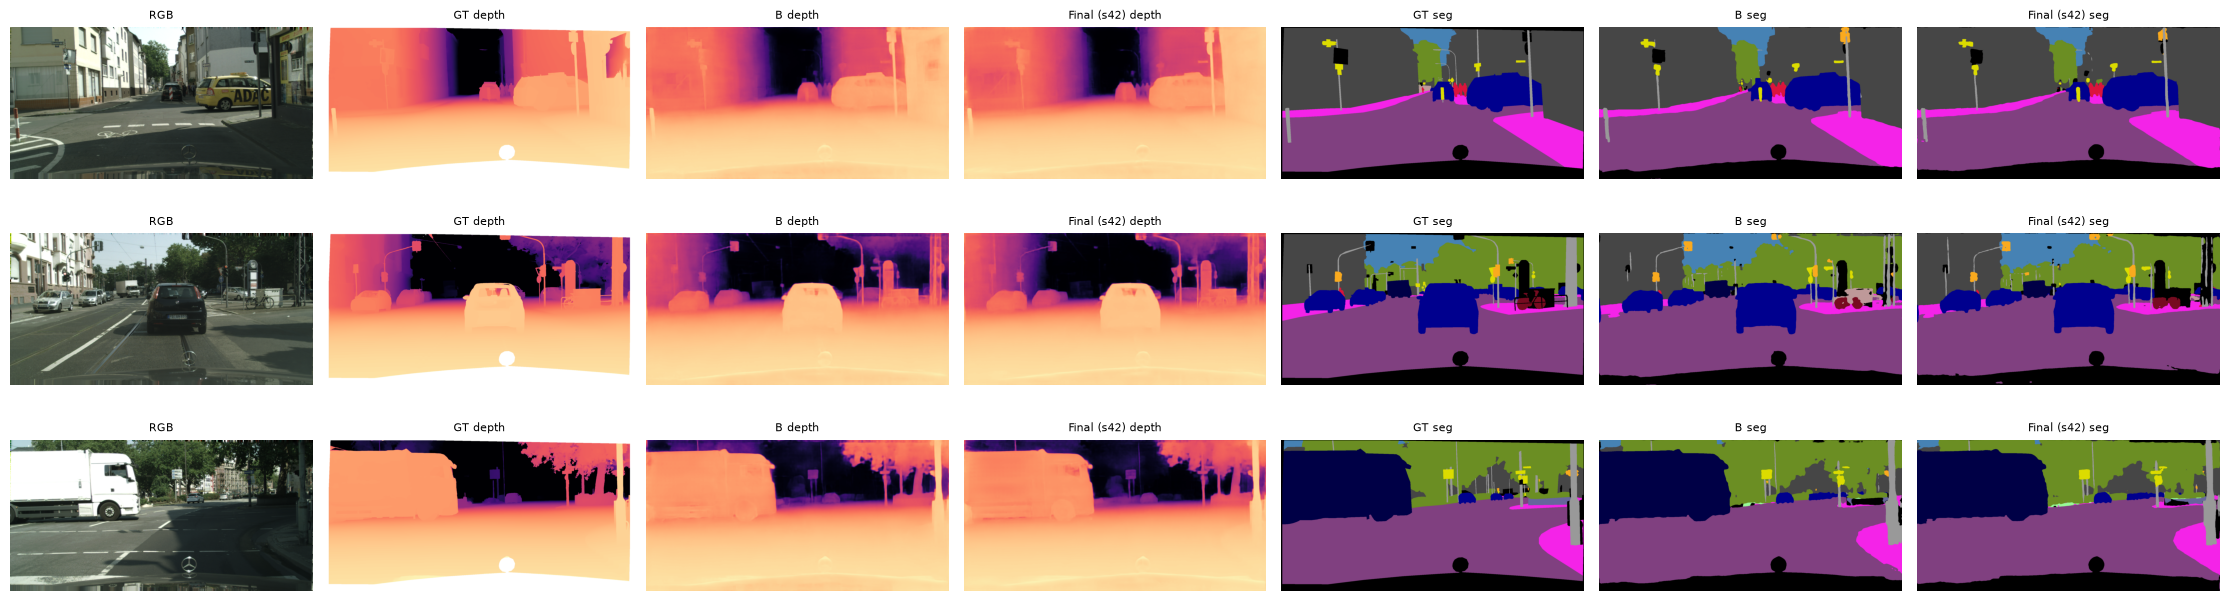

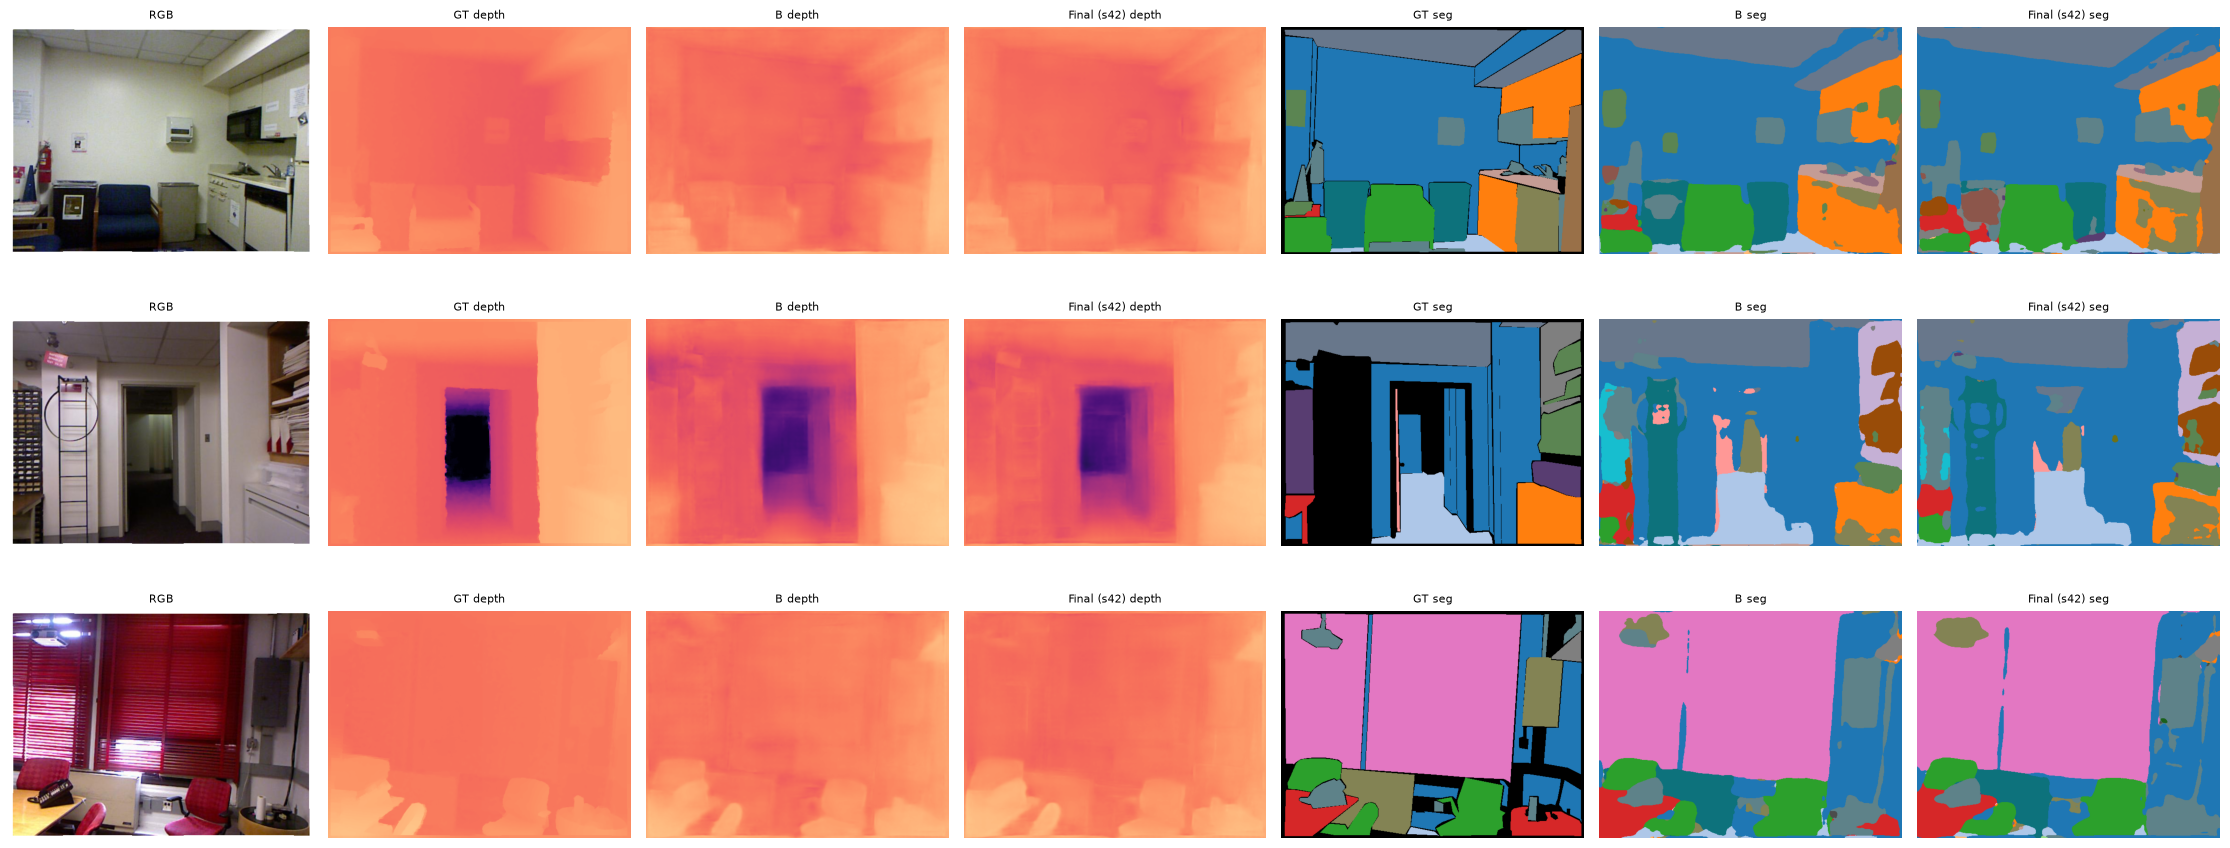

In [22]:
@torch.no_grad()
def show_qualitative_final(dataset: str, indices: Sequence[int] = (0, 7, 21)) -> None:
    configure()
    eval_dataset = make_dataset(dataset, CFG["datasets"][dataset]["eval_split"], train=False)
    models = {}
    if (CFG["ckpt_root"] / run_name(dataset, "partial_ft") / "final.pt").exists():
        models["B"] = load_trained(dataset, "partial_ft")
    variant = final_setup(dataset, 42)
    models["Final (s42)"] = load_trained(dataset, variant)
    configure()

    max_depth = CFG["datasets"][dataset]["max_depth"]
    palette = PALETTES[dataset]
    n_cols = 2 + 2 * len(models) + 1
    fig, axs = plt.subplots(len(indices), n_cols, squeeze=False)
    fig.set_size_inches(3.2 * n_cols, 2.2 * len(indices) * (1 if dataset == "cityscapes" else 1.4))
    for row, i in enumerate(indices):
        sample = eval_dataset[i]
        gt_depth, gt_seg = sample["depth"].numpy(), sample["seg"].numpy()
        gt_depth = gt_depth[0] if gt_depth.ndim == 3 else gt_depth
        panels = [("RGB", denormalize(sample["image"]), False), ("GT depth", np.where(gt_depth > 0, gt_depth, np.nan), True)]
        segs = {}
        for name, model in models.items():
            depth, probs = predict(model, sample["image"][None].to(device))
            panels.append((f"{name} depth", F.interpolate(depth, size=gt_depth.shape, mode="bilinear", align_corners=False)[0, 0].cpu().numpy(), True))
            segs[name] = F.interpolate(probs, size=gt_depth.shape, mode="bilinear", align_corners=False)[0].argmax(0).cpu().numpy()
        panels.append(("GT seg", colorize_seg(gt_seg, palette), False))
        panels += [(f"{name} seg", colorize_seg(s, palette), False) for name, s in segs.items()]
        for col, (title, image, is_depth) in enumerate(panels):
            axs[row, col].imshow(image, cmap="magma_r", vmin=0, vmax=max_depth) if is_depth else axs[row, col].imshow(image)
            axs[row, col].set_title(title, fontsize=8)
            axs[row, col].axis("off")
    plt.tight_layout()
    fig.savefig(COMPARE_DIR / f"final_qualitative_{dataset}.png", dpi=110)
    plt.show()
    del models
    torch.cuda.empty_cache()


show_qualitative_final("cityscapes")
show_qualitative_final("nyu")